# Modelo de regresión lineal: selección de variables y estructura del modelo

El gerente de CasaRoble quiere predecir el precio de venta de una vivienda a partir de sus características
y de las del conjunto residencial donde se ubica. Este notebook continúa el análisis exploratorio de
`Problema_de_regresion_completo.ipynb`:

1. **Selección de las variables**: qué variable respuesta y qué variables explicativas entran al modelo, y por qué.
2. **Determinación de la estructura**: transformaciones, forma funcional, variables indicadoras,
   interacciones y estructura del término de error.

Al final se estima el modelo resultante, que es el punto de partida para la verificación de supuestos,
los intervalos de confianza, las pruebas de hipótesis y la interpretación, y se generan las predicciones
para la competencia de Kaggle (métrica: error cuadrático medio).

**Contenido**

1. Datos y hallazgos del análisis exploratorio
2. Selección de variables
3. Determinación de la estructura del modelo
4. Predicciones para la competencia

## 1. Datos y hallazgos del análisis exploratorio

In [2]:
import os
import warnings
from itertools import combinations, product
from pathlib import Path

warnings.filterwarnings("ignore")

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from dotenv import load_dotenv
from patsy import dmatrix
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LassoCV
from sklearn.model_selection import GroupKFold, KFold, LeaveOneOut
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

# Paleta y estilo comunes para las figuras
AZUL, NARANJA, AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e5e5e5"


def estilo(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)

In [3]:
env_path = Path.cwd() / ".env"
if not env_path.is_file():
    raise FileNotFoundError("No se encontro .env")
load_dotenv(env_path, override=True)
if not os.environ.get("KAGGLE_API_TOKEN", "").strip():
    raise ValueError("Falta KAGGLE_API_TOKEN en el archivo .env.")

data_dir = Path(kagglehub.competition_download("mae-competencia-regresion-202620"))
df_train = pd.read_csv(data_dir / "Train real state.csv")
df_test = pd.read_csv(data_dir / "Test real state.csv")
print("Entrenamiento (filas, columnas):", df_train.shape)
print("Prueba (filas, columnas):", df_test.shape)

Entrenamiento (filas, columnas): (4124, 31)
Prueba (filas, columnas): (1767, 30)


La limpieza es la misma del análisis exploratorio: se unifica el formato de `TimeToSubway`
(las filas `no_bus_stop_nearby` corresponden a viviendas sin metro cercano) y se calcula la antigüedad
de la vivienda al momento de la venta. Además los nombres de columna se reescriben sin puntos para poder usarlos en fórmulas y las variables categóricas se fijan con los mismos niveles en entrenamiento y prueba.

In [4]:
orden_metro = ["0~5min", "5min~10min", "10min~15min", "15min~20min", "no_subway_nearby"]
categoricas = ["HallwayType", "HeatingType", "AptManageType", "TimeToBusStop", "TimeToSubway", "SubwayStation"]


def limpiar(df):
    df = df.copy()
    df["TimeToSubway"] = df["TimeToSubway"].replace({"0-5min": "0~5min", "no_bus_stop_nearby": "no_subway_nearby"})
    df["Antiguedad"] = df["YrSold"] - df["YearBuilt"]
    df.columns = [c.rstrip(".").replace(".", "_") for c in df.columns]
    return df


train = limpiar(df_train)
test = limpiar(df_test)
for col in categoricas:
    niveles = orden_metro if col == "TimeToSubway" else sorted(set(train[col]) | set(test[col]))
    train[col] = pd.Categorical(train[col], categories=niveles)
    test[col] = pd.Categorical(test[col], categories=niveles)

train["logPrice"] = np.log(train["SalePrice"])
train["logSize"] = np.log(train["Size_sqf"])
test["logSize"] = np.log(test["Size_sqf"])
print("Valores nulos en train / test:", int(train.isna().sum().sum()), "/", int(test.isna().sum().sum()))

Valores nulos en train / test: 0 / 0


In [5]:
# Hallazgos del análisis exploratorio que condicionan el modelo
print("Asimetria del precio:", round(train["SalePrice"].skew(), 2),
      "- asimetria del logaritmo del precio:", round(train["logPrice"].skew(), 2))

numericas = train.select_dtypes("number").columns.drop(["id", "SalePrice", "logPrice", "logSize"])
correlaciones = pd.DataFrame({
    "Pearson con log(precio)": train[numericas].corrwith(train["logPrice"]),
    "Spearman con log(precio)": train[numericas].corrwith(train["logPrice"], method="spearman"),
}).sort_values("Pearson con log(precio)", key=abs, ascending=False)
correlaciones.round(3)

Asimetria del precio: 0.48 - asimetria del logaritmo del precio: -0.67


,Pearson con log(precio),Spearman con log(precio)
Size_sqf,0.696,0.709
N_FacilitiesInApt,0.498,0.506
N_FacilitiesNearBy_PublicOffice,-0.494,-0.486
N_FacilitiesNearBy_Total,-0.454,-0.392
N_Parkinglot_Basement,0.453,0.421
YearBuilt,0.449,0.493
N_FacilitiesNearBy_ETC,-0.434,-0.503
N_SchoolNearBy_University,-0.400,-0.402
YrSold,0.367,0.372
N_SchoolNearBy_Total,-0.365,-0.383


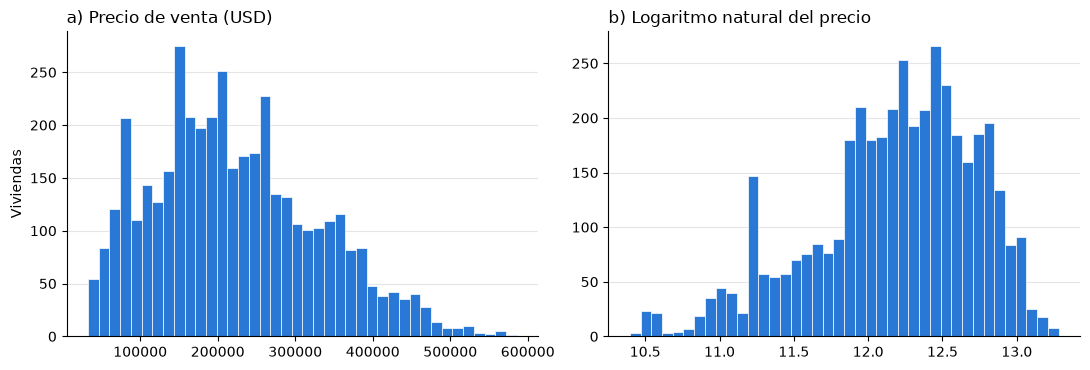

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(train["SalePrice"], bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
axes[0].set_title("a) Precio de venta (USD)", loc="left")
axes[0].set_ylabel("Viviendas")
axes[1].hist(train["logPrice"], bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
axes[1].set_title("b) Logaritmo natural del precio", loc="left")
for ax in axes:
    estilo(ax)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Hallazgos del análisis exploratorio que se trasladan al modelo**

* No hay valores faltantes en entrenamiento ni en prueba.
* El tamaño es la variable con mayor asociación con el precio (Pearson = 0,696 con el log del precio).
  Le siguen variables que describen el conjunto residencial: instalaciones del conjunto (0,498),
  oficinas públicas cercanas (−0,494), total de instalaciones cercanas (−0,454),
  parqueaderos en sótano (0,453) y año de construcción (0,449).
* El precio tiene asimetría positiva moderada (0,48) y su logaritmo tiene asimetría negativa (−0,67).
  La distribución marginal de la respuesta no decide la escala del modelo, porque los supuestos se refieren
  a los residuos. La escala se decide en la sección 3.1.
* Varias explicativas están fuertemente correlacionadas entre sí, y hay 300 filas idénticas a otra salvo
  por el `id`. La sección 2 explica ambos hechos.

## 2. Selección de variables

**Variable respuesta.** El precio de venta (`SalePrice`) es la variable que el gerente quiere predecir.
Mientras se seleccionan las variables, el precio se modela en logaritmo. Los efectos de las características
sobre el precio son de tipo proporcional (un pie cuadrado adicional vale más en un conjunto caro que en uno
barato) y en escala original la varianza crece con el nivel del precio. La sección 3.1 evalúa formalmente
la escala con la familia de transformaciones de Box-Cox.

**Variables explicativas.** Siguiendo la lógica de los precios hedónicos, el precio de una vivienda depende
de sus atributos (tamaño, piso), de los atributos del conjunto residencial (antigüedad, tipología, escala,
dotaciones), de la ubicación (metro, bus, servicios cercanos) y del momento de la venta. Las 29 columnas
disponibles se evalúan en cinco pasos: nivel de observación, dependencias exactas, multicolinealidad,
criterios de selección y contraste de las variables excluidas.

### 2.1 Nivel de observación de las variables candidatas

In [7]:
# Un conjunto residencial se identifica por año de construccion, estacion y parqueaderos (analisis exploratorio)
llave_complejo = ["YearBuilt", "SubwayStation", "N_Parkinglot_Ground", "N_Parkinglot_Basement"]
claves = (pd.concat([train[llave_complejo], test[llave_complejo]])
          .drop_duplicates().sort_values(llave_complejo).reset_index(drop=True))
claves["complejo"] = np.arange(len(claves))
train = train.merge(claves, on=llave_complejo, how="left")
test = test.merge(claves, on=llave_complejo, how="left")
print("Conjuntos residenciales en train:", train["complejo"].nunique(),
      "- en test:", test["complejo"].nunique(),
      "- conjuntos de test que no estan en train:", len(set(test["complejo"]) - set(train["complejo"])))

candidatas = [c for c in train.columns if c not in ["id", "SalePrice", "logPrice", "logSize", "complejo"]]
nivel = pd.DataFrame({
    "Valores distintos": train[candidatas].nunique(),
    "Conjuntos en los que varia": [int((train.groupby("complejo", observed=True)[c].nunique() > 1).sum())
                                   for c in candidatas],
})
nivel["Nivel"] = np.where(nivel["Conjuntos en los que varia"] == 0, "Conjunto", "Vivienda / venta")
nivel.sort_values(["Nivel", "Valores distintos"], ascending=[False, False])

Conjuntos residenciales en train: 26 - en test: 26 - conjuntos de test que no estan en train: 0


,Valores distintos,Conjuntos en los que varia,Nivel
Size_sqf,88,25,Vivienda / venta
Floor,43,26,Vivienda / venta
Antiguedad,40,26,Vivienda / venta
MonthSold,12,26,Vivienda / venta
YrSold,11,26,Vivienda / venta
N_Parkinglot_Ground,23,0,Conjunto
N_Parkinglot_Basement,20,0,Conjunto
YearBuilt,16,0,Conjunto
N_SchoolNearBy_Total,14,0,Conjunto
N_elevators,13,0,Conjunto


In [8]:
# Porcentaje de la varianza que ocurre entre conjuntos: R2 de cada variable sobre el indicador de conjunto
entre_conjuntos = pd.Series({
    col: smf.ols(f"{col} ~ C(complejo)", train).fit().rsquared * 100
    for col in ["logPrice", "Size_sqf", "Floor", "Antiguedad", "YrSold", "MonthSold"]
})
entre_conjuntos.round(1).to_frame("% de la varianza entre conjuntos")

,% de la varianza entre conjuntos
logPrice,67.7
Size_sqf,51.7
Floor,16.5
Antiguedad,91.5
YrSold,25.6
MonthSold,8.3


**Interpretación.** Las combinaciones de año de construcción, estación y parqueaderos identifican
26 conjuntos residenciales y todos los conjuntos de prueba aparecen en entrenamiento.
Las variables se dividen en dos niveles:

* **Vivienda / venta** (5 variables): tamaño, piso, año, mes de venta y antigüedad al vender.
  Cambian de una venta a otra dentro de un mismo conjunto.
* **Conjunto** (25 variables): tipología, calefacción, administración, accesibilidad, estación, parqueaderos,
  número de apartamentos, administradores, ascensores, instalaciones y servicios cercanos.
  Son constantes dentro de cada conjunto.

El 67,7 % de la varianza del log-precio ocurre entre conjuntos. La antigüedad es casi una característica
del conjunto (91,5 % de su varianza es entre conjuntos), porque dentro de un conjunto solo cambia con el año
de venta.

**Consecuencia para la selección.** Las 4.124 ventas aportan 4.124 observaciones para estimar el efecto
del tamaño o del piso, para estimar el efecto de una característica del conjunto solo hay 26 unidades
independientes. Un criterio que trate las 4.124 filas como independientes sobrestima la información
disponible sobre esas características y tiende a incluir demasiadas.

### 2.2 Dependencias exactas entre las candidatas

In [9]:
instalaciones = ["N_FacilitiesNearBy_PublicOffice", "N_FacilitiesNearBy_Hospital", "N_FacilitiesNearBy_Dpartmentstore",
                 "N_FacilitiesNearBy_Mall", "N_FacilitiesNearBy_ETC", "N_FacilitiesNearBy_Park"]
escuelas = ["N_SchoolNearBy_Elementary", "N_SchoolNearBy_Middle", "N_SchoolNearBy_High", "N_SchoolNearBy_University"]
print("Filas en que el total de instalaciones difiere de la suma:",
      int((train[instalaciones].sum(axis=1) != train["N_FacilitiesNearBy_Total"]).sum()))
print("Filas en que el total de escuelas difiere de la suma:",
      int((train[escuelas].sum(axis=1) != train["N_SchoolNearBy_Total"]).sum()))
print("Filas en que Antiguedad difiere de YrSold - YearBuilt:",
      int((train["Antiguedad"] != train["YrSold"] - train["YearBuilt"]).sum()))

# Rango de la matriz de diseno con todas las candidatas (las categoricas entran como indicadoras)
X_todas = dmatrix(" + ".join(candidatas), train, return_type="dataframe")
print("\nMatriz con todas las candidatas: columnas", X_todas.shape[1], "- rango", np.linalg.matrix_rank(X_todas))

variables_conjunto = nivel.index[nivel["Nivel"] == "Conjunto"].tolist()
tabla_conjuntos = train.groupby("complejo")[variables_conjunto].first()
X_conjunto = dmatrix(" + ".join(variables_conjunto), tabla_conjuntos, return_type="dataframe")
print("Variables de conjunto (una fila por conjunto): filas", X_conjunto.shape[0],
      "- columnas", X_conjunto.shape[1], "- rango", np.linalg.matrix_rank(X_conjunto))

Filas en que el total de instalaciones difiere de la suma: 0
Filas en que el total de escuelas difiere de la suma: 0
Filas en que Antiguedad difiere de YrSold - YearBuilt: 0

Matriz con todas las candidatas: columnas 42 - rango 29
Variables de conjunto (una fila por conjunto): filas 26 - columnas 37 - rango 25


**Interpretación.** Hay tres dependencias lineales exactas:

1. Los totales de instalaciones y de escuelas cercanas son exactamente la suma de sus componentes.
2. `Antiguedad = YrSold − YearBuilt` en todas las filas.
3. Con 26 conjuntos las variables de conjunto pueden aportar como máximo 25 columnas independientes
   además del intercepto. La tabla de variables de conjunto (37 columnas, una fila por conjunto)
   tiene rango 25 y la matriz de diseño con todas las candidatas tiene 42 columnas pero rango 29.
   Si se incluyen todas, los coeficientes no están identificados.

**Decisiones de esta etapa**

| Variable | Decisión | Razón |
|---|---|---|
| `id` | Excluida | Identificador sin contenido explicativo. |
| 6 componentes de instalaciones cercanas y 4 de escuelas cercanas | Representados por sus totales | Son linealmente dependientes de los totales. Con 26 conjuntos no hay grados de libertad para 10 variables de entorno. |
| `YearBuilt` | Representado por `Antiguedad` | Con `YrSold` en el modelo contienen la misma información, y la antigüedad es más fácil de interpretar. |
| Resto | Candidatas | 4 variables de vivienda y venta (tamaño, piso, año y mes) y 15 grupos de conjunto, incluida la antigüedad. Se evalúan en las secciones 2.4 a 2.8. |

### 2.3 Variable derivada: ventas en bloque

In [10]:
ventas_mes = train.groupby(["complejo", "YrSold", "MonthSold"]).size().rename("Ventas")
print("Ventas por conjunto y mes: mediana", int(ventas_mes.median()), "- percentil 99", int(ventas_mes.quantile(0.99)),
      "- maximo", int(ventas_mes.max()))
display(ventas_mes.sort_values(ascending=False).head(5).to_frame())

# Eventos: un conjunto con 100 o mas ventas en un mismo mes
eventos = ventas_mes[ventas_mes >= 100].index


def marcar_bloque(df):
    return df.set_index(["complejo", "YrSold", "MonthSold"]).index.isin(eventos).astype(int)


train["Bloque"] = marcar_bloque(train)
test["Bloque"] = marcar_bloque(test)

columnas_originales = [c.rstrip(".").replace(".", "_") for c in df_train.columns if c != "id"]
repetidas = train.duplicated(subset=columnas_originales, keep=False)
precio_pie2 = train["SalePrice"] / train["Size_sqf"]
filas = []
for complejo, anio, mes in eventos:
    mismo_anio = (train["complejo"] == complejo) & (train["YrSold"] == anio)
    en_evento = mismo_anio & (train["MonthSold"] == mes)
    filas.append({
        "Conjunto": complejo, "Año": anio, "Mes": mes, "Ventas": int(en_evento.sum()),
        "Filas repetidas": int((en_evento & repetidas).sum()),
        "USD/pie2 mediano en el evento": precio_pie2[en_evento].median(),
        "USD/pie2 mediano, resto de ventas del conjunto ±1 año": precio_pie2[
            (train["complejo"] == complejo) & train["YrSold"].between(anio - 1, anio + 1) & ~en_evento].median(),
    })
display(pd.DataFrame(filas).round(1))
print("Filas repetidas en train:", int(repetidas.sum()), "- de ellas en los dos eventos:",
      int((repetidas & (train["Bloque"] == 1)).sum()))
print("Ventas marcadas como Bloque en train / test:", int(train["Bloque"].sum()), "/", int(test["Bloque"].sum()))

Ventas por conjunto y mes: mediana 2 - percentil 99 12 - maximo 178


,,,Ventas
complejo,YrSold,MonthSold,
19,2016,1,178
10,2010,5,113
18,2009,7,44
19,2013,5,40
15,2008,10,28


,Conjunto,Año,Mes,Ventas,Filas repetidas,USD/pie2 mediano en el evento,"USD/pie2 mediano, resto de ventas del conjunto ±1 año"
0,10,2010,5,113,93,132.0,186.9
1,19,2016,1,178,147,231.8,389.0


Filas repetidas en train: 300 - de ellas en los dos eventos: 240
Ventas marcadas como Bloque en train / test: 291 / 25


**Interpretación.** Lo usual es que un conjunto registre dos ventas en un mes (percentil 99: 12 ventas).
Dos meses se salen por completo de ese patrón:

* Conjunto 10, mayo de 2010: 113 ventas.
* Conjunto 19, enero de 2016: 178 ventas.

En esos eventos el precio por pie cuadrado fue mucho menor que en las demás ventas del mismo conjunto en
 el rango de un más o menos 1 año (132 frente a 187 USD/pie² y 232 frente a 389 USD/pie²), además 240 de las 300 filas repetidas pertenecen a estos dos eventos, por lo que todo indica ventas masivas de unidades similares a precio de lote, más no errores de registro.

Se crea la variable indicadora `Bloque` que vale 1 si la venta pertenece a uno de estos eventos.
Los eventos se identifican con los datos de entrenamiento y en prueba se marcan las ventas del mismo
conjunto y mes: 291 ventas en entrenamiento y 25 en prueba. La regla no usa el precio solo el conjunto
y la fecha, así que puede aplicarse a cualquier venta nueva, su aporte se contrasta en la sección 3.3.

### 2.4 Multicolinealidad entre las variables de conjunto

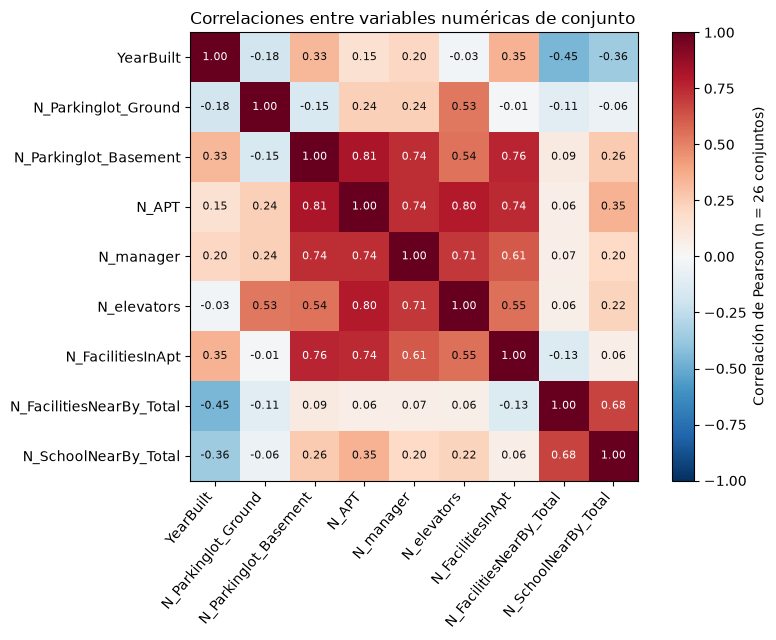

In [11]:
# Correlaciones calculadas sobre los 26 conjuntos (una fila por conjunto)
numericas_conjunto = ["YearBuilt", "N_Parkinglot_Ground", "N_Parkinglot_Basement", "N_APT", "N_manager",
                      "N_elevators", "N_FacilitiesInApt", "N_FacilitiesNearBy_Total", "N_SchoolNearBy_Total"]
matriz = tabla_conjuntos[numericas_conjunto].corr()

fig, ax = plt.subplots(figsize=(8.5, 6.5))
imagen = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz)), labels=matriz.columns, rotation=50, ha="right")
ax.set_yticks(range(len(matriz)), labels=matriz.index)
for i in range(len(matriz)):
    for j in range(len(matriz)):
        valor = matriz.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valor) > 0.6 else TINTA)
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson (n = 26 conjuntos)")
ax.set_title("Correlaciones entre variables numéricas de conjunto", loc="left")
plt.tight_layout()
plt.show()

In [12]:
def gvif(datos, terminos):
    """GVIF de Fox y Monette para cada termino; GVIF^(1/(2gl)) es comparable con la raiz del VIF."""
    X = dmatrix(" + ".join(terminos.values()), datos, return_type="dataframe")
    cortes = X.design_info.term_name_slices
    X = X.drop(columns="Intercept")
    R = np.corrcoef(X.to_numpy(), rowvar=False)
    signo, log_det = np.linalg.slogdet(R)
    filas = {}
    for nombre, termino in terminos.items():
        cols = [c - 1 for c in range(*cortes[termino].indices(X.shape[1] + 1))]
        resto = [c for c in range(X.shape[1]) if c not in cols]
        log_gvif = (np.linalg.slogdet(R[np.ix_(cols, cols)])[1] + np.linalg.slogdet(R[np.ix_(resto, resto)])[1]
                    - log_det) if signo > 0 else np.inf
        valor = np.exp(log_gvif)
        filas[nombre] = {"gl": len(cols), "GVIF": valor, "GVIF^(1/(2gl))": valor ** (1 / (2 * len(cols)))}
    return pd.DataFrame(filas).T


terminos_vivienda = {"logSize": "logSize", "Floor": "Floor", "YrSold": "C(YrSold)", "MonthSold": "MonthSold",
                     "Bloque": "Bloque"}
grupos_conjunto = {
    "Antiguedad": "Antiguedad", "HallwayType": "C(HallwayType)", "HeatingType": "C(HeatingType)",
    "AptManageType": "C(AptManageType)", "TimeToSubway": "C(TimeToSubway)", "TimeToBusStop": "C(TimeToBusStop)",
    "SubwayStation": "C(SubwayStation)", "N_Parkinglot_Ground": "N_Parkinglot_Ground",
    "N_Parkinglot_Basement": "N_Parkinglot_Basement", "N_APT": "N_APT", "N_manager": "N_manager",
    "N_elevators": "N_elevators", "N_FacilitiesInApt": "N_FacilitiesInApt",
    "N_FacilitiesNearBy_Total": "N_FacilitiesNearBy_Total", "N_SchoolNearBy_Total": "N_SchoolNearBy_Total",
}
X_vif = dmatrix(" + ".join({**terminos_vivienda, **grupos_conjunto}.values()), train, return_type="dataframe")
print("Con todas las candidatas: columnas", X_vif.shape[1], "- rango", np.linalg.matrix_rank(X_vif),
      "-> la matriz de correlaciones es singular y el GVIF es infinito para todas las variables\n")

# Eliminacion mecanica: se retira la variable de conjunto con mayor GVIF^(1/(2gl)) hasta que todas queden bajo raiz(5)
actuales = dict(grupos_conjunto)
while True:
    tabla = gvif(train, {**terminos_vivienda, **actuales}).loc[list(actuales), "GVIF^(1/(2gl))"]
    if tabla.max() < np.sqrt(5):
        break
    print(f"Se retira {tabla.idxmax():<26} GVIF^(1/(2gl)) = {tabla.max():.2f}")
    del actuales[tabla.idxmax()]
print("Quedan:", list(actuales))

Con todas las candidatas: columnas 41 - rango 39 -> la matriz de correlaciones es singular y el GVIF es infinito para todas las variables

Se retira Antiguedad                 GVIF^(1/(2gl)) = inf
Se retira HallwayType                GVIF^(1/(2gl)) = inf
Se retira N_elevators                GVIF^(1/(2gl)) = 19.44
Se retira N_APT                      GVIF^(1/(2gl)) = 8.61
Se retira N_SchoolNearBy_Total       GVIF^(1/(2gl)) = 7.04
Se retira N_Parkinglot_Basement      GVIF^(1/(2gl)) = 5.25
Se retira N_FacilitiesInApt          GVIF^(1/(2gl)) = 2.79
Se retira TimeToSubway               GVIF^(1/(2gl)) = 2.44
Quedan: ['HeatingType', 'AptManageType', 'TimeToBusStop', 'SubwayStation', 'N_Parkinglot_Ground', 'N_manager', 'N_FacilitiesNearBy_Total']


**Interpretación.** Con 26 conjuntos, las variables de conjunto forman bloques muy correlacionados:

* **Escala y dotaciones.** Parqueaderos en sótano, número de apartamentos, administradores, ascensores
  e instalaciones del conjunto tienen correlaciones de 0,54 a 0,81, por lo que se afirma que todas miden lo mismo:
  conjuntos grandes y bien dotados.
* **Entorno.** El total de instalaciones cercanas y el total de escuelas cercanas tienen r = 0,68.
  Ambos se relacionan negativamente con el año de construcción (−0,45 y −0,36): los conjuntos antiguos
  están en zonas más consolidadas.

Con todas las candidatas la matriz es singular (41 columnas, rango 39) y el GVIF es infinito para todas
las variables. La regla mecánica de retirar la variable con mayor GVIF empieza entonces por las dos primeras
de la lista con GVIF infinito, `Antiguedad` y `HallwayType`. Es una elección arbitraria que descarta la variable
de conjunto más asociada con el precio, y todas las eliminaciones siguientes dependen de ese orden.El VIF sirve aquí para diagnosticar redundancias y no como regla automática. 

**Conclusión:** de cada bloque redundante debe entrar a lo sumo una variable. La elección se hace con los criterios de las secciones siguientes.

### 2.5 Selección con los criterios clásicos

Las variables de vivienda y de tiempo se mantienen fijas en una especificación de trabajo
(`logSize`, su cuadrado, `Floor`, indicadoras de año, `MonthSold` y `Bloque`, donde su forma se justifica en la
sección 3) y se buscan las variables de conjunto entre los 15 grupos candidatos. Cada variable categórica
entra o sale con todas sus indicadoras. Se ajustan los $2^{15} = 32\,768$ modelos posibles (mejores
subconjuntos) y se comparan con:

* $R^2$ ajustado, $C_p$ de Mallows, AIC y BIC, que suponen observaciones independientes.
* Validación cruzada de 10 pliegues aleatorios (**VC-10**): mide el error al predecir ventas nuevas
  de los mismos conjuntos.
* Validación cruzada dejando un conjunto por fuera (**VC-conjunto**, 26 pliegues): mide el error
  al predecir un conjunto que el modelo no ha visto, es decir, si el efecto estimado de una característica
  del conjunto se generaliza.

In [13]:
base_vivienda = "logSize + I(logSize ** 2) + Floor + C(YrSold) + MonthSold + Bloque"
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
por_conjunto = GroupKFold(n_splits=train["complejo"].nunique())

# Matriz con todas las columnas, cada modelo usa un subconjunto de ellas
X = dmatrix(base_vivienda + " + " + " + ".join(grupos_conjunto.values()), train, return_type="dataframe")
cortes = X.design_info.term_name_slices
columnas_grupo = {g: list(range(X.shape[1]))[cortes[t]] for g, t in grupos_conjunto.items()}
columnas_base = [i for i in range(X.shape[1]) if not any(i in c for c in columnas_grupo.values())]
Z = X.to_numpy().copy()
Z[:, 1:] = (Z[:, 1:] - Z[:, 1:].mean(axis=0)) / Z[:, 1:].std(axis=0)
y = train["logPrice"].to_numpy()
n = len(y)


def productos(filas):
    return Z[filas].T @ Z[filas], Z[filas].T @ y[filas], y[filas] @ y[filas]


def resolver(A, b):
    return np.linalg.solve(A + 1e-8 * np.eye(len(b)), b)


ZtZ, Zty, yty = productos(np.arange(n))
bloques_conjunto = [productos(valida) for _, valida in por_conjunto.split(Z, groups=train["complejo"])]
bloques_kfold = [productos(valida) for _, valida in kfold.split(Z)]


def formato_error(valor):
    """RMSE con 4 decimales; los valores que explotan por falta de identificacion se marcan."""
    return f"{valor:.4f}" if valor < 10 else f"{valor:.1e} (explota)"


def rmse_validacion(cols, bloques):
    sse = 0.0
    for A_v, b_v, c_v in bloques:
        beta = resolver(ZtZ[np.ix_(cols, cols)] - A_v[np.ix_(cols, cols)], Zty[cols] - b_v[cols])
        sse += c_v - 2 * beta @ b_v[cols] + beta @ A_v[np.ix_(cols, cols)] @ beta
    return np.sqrt(sse / n)


# Varianza del error del modelo con un indicador por conjunto (saturado en el nivel conjunto) para el Cp
s2_saturado = smf.ols("logPrice ~ C(complejo) + " + base_vivienda, train).fit().mse_resid
sst = ((y - y.mean()) ** 2).sum()
nombres_grupos = list(grupos_conjunto)
filas = []
for k in range(len(nombres_grupos) + 1):
    for S in combinations(nombres_grupos, k):
        cols = sorted(columnas_base + sum((columnas_grupo[g] for g in S), []))
        A = ZtZ[np.ix_(cols, cols)]
        beta = resolver(A, Zty[cols])
        sse = yty - 2 * beta @ Zty[cols] + beta @ A @ beta
        p = np.linalg.matrix_rank(A)
        filas.append({"k": k, "p": p, "sse": sse, "variables": S, "cols": cols})
subconjuntos = pd.DataFrame(filas)
subconjuntos["R2 ajustado"] = 1 - (subconjuntos["sse"] / (n - subconjuntos["p"])) / (sst / (n - 1))
subconjuntos["Cp"] = subconjuntos["sse"] / s2_saturado - n + 2 * subconjuntos["p"]
subconjuntos["AIC"] = n * np.log(subconjuntos["sse"] / n) + 2 * subconjuntos["p"]
subconjuntos["BIC"] = n * np.log(subconjuntos["sse"] / n) + np.log(n) * subconjuntos["p"]

mejores = subconjuntos.loc[subconjuntos.groupby("k")["BIC"].idxmin()].copy()
mejores["RMSE VC-10"] = [rmse_validacion(c, bloques_kfold) for c in mejores["cols"]]
mejores["RMSE VC-conjunto"] = [rmse_validacion(c, bloques_conjunto) for c in mejores["cols"]]
mejores["variables"] = mejores["variables"].apply(", ".join)
mejores["VC-conjunto"] = mejores["RMSE VC-conjunto"].apply(formato_error)
print("Modelos ajustados:", len(subconjuntos))
print("Mejor modelo de cada tamaño k (numero de variables de conjunto) segun BIC:")
display(mejores[["k", "p", "R2 ajustado", "Cp", "AIC", "BIC", "RMSE VC-10", "VC-conjunto", "variables"]]
        .set_index("k").round(4))
for criterio, sentido in [("R2 ajustado", "idxmax"), ("Cp", "idxmin"), ("AIC", "idxmin"), ("BIC", "idxmin")]:
    elegido = subconjuntos.loc[getattr(subconjuntos[criterio], sentido)()]
    print(f"Mejor segun {criterio:<12}: {elegido['k']} variables de conjunto")

Modelos ajustados: 32768
Mejor modelo de cada tamaño k (numero de variables de conjunto) segun BIC:


,p,R2 ajustado,Cp,AIC,BIC,RMSE VC-10,VC-conjunto,variables
k,,,,,,,,
0,16,0.8089,15788.9596,-11719.4672,-11618.2739,0.2419,0.2906,
1,17,0.9237,3849.5552,-15502.9083,-15395.3905,0.1528,0.1867,Antiguedad
2,24,0.9396,2192.2362,-16463.6662,-16311.8763,0.1360,0.8099,"Antiguedad, SubwayStation"
3,26,0.9452,1613.9867,-16861.7164,-16697.2773,0.1297,0.8076,"Antiguedad, HallwayType, SubwayStation"
4,29,0.9486,1266.0636,-17120.7508,-16937.3380,0.1257,3.3392,"Antiguedad, HallwayType, TimeToSubway, SubwayStation"
5,29,0.9506,1052.1707,-17289.5924,-17106.1797,0.1232,1.4281,"HallwayType, TimeToBusStop, SubwayStation, N_Parkinglot_Ground, N_APT"
6,30,0.9528,831.7010,-17470.8614,-17281.1240,0.1206,1.4230,"Antiguedad, HallwayType, TimeToBusStop, SubwayStation, N_Parkinglot_Ground, N_APT"
7,32,0.9542,686.6036,-17594.4091,-17392.0226,0.1188,3.7845,"Antiguedad, HeatingType, AptManageType, TimeToSubway, SubwayStation, N_elevators, N_FacilitiesInApt"
8,34,0.9563,465.1808,-17791.0669,-17576.0313,0.1160,4.1014,"HeatingType, AptManageType, TimeToSubway, TimeToBusStop, SubwayStation, N_APT, N_manager, N_elevators"


Mejor segun R2 ajustado : 12 variables de conjunto
Mejor segun Cp          : 12 variables de conjunto
Mejor segun AIC         : 12 variables de conjunto
Mejor segun BIC         : 12 variables de conjunto


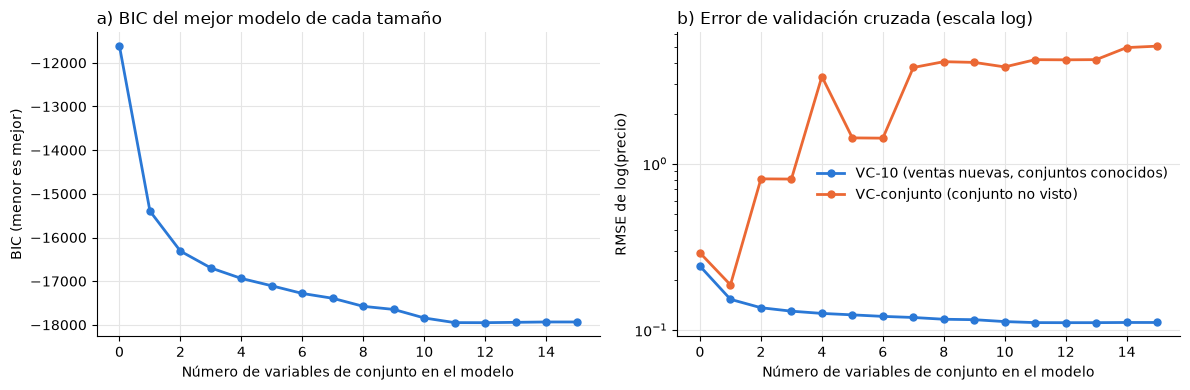

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(mejores["k"], mejores["BIC"], color=AZUL, marker="o", markersize=5, linewidth=2)
axes[0].set_title("a) BIC del mejor modelo de cada tamaño", loc="left")
axes[0].set_ylabel("BIC (menor es mejor)")
axes[1].plot(mejores["k"], mejores["RMSE VC-10"], color=AZUL, marker="o", markersize=5, linewidth=2,
             label="VC-10 (ventas nuevas, conjuntos conocidos)")
axes[1].plot(mejores["k"], mejores["RMSE VC-conjunto"], color=NARANJA, marker="o", markersize=5, linewidth=2,
             label="VC-conjunto (conjunto no visto)")
axes[1].set_yscale("log")
axes[1].set_title("b) Error de validación cruzada (escala log)", loc="left")
axes[1].set_ylabel("RMSE de log(precio)")
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xlabel("Número de variables de conjunto en el modelo")
    estilo(ax)
plt.tight_layout()
plt.show()

In [15]:
def ajustar(formula, datos=None, robusto=True):
    """MCO; por defecto con errores estandar agrupados por conjunto (t con G - 1 grados de libertad)."""
    datos = train if datos is None else datos
    if not robusto:
        return smf.ols(formula, datos).fit()
    return smf.ols(formula, datos).fit(cov_type="cluster", cov_kwds={"groups": datos["complejo"]}, use_t=True)


# Seleccion hacia adelante con AIC (observaciones tratadas como independientes)
seleccion, aic_actual, pasos = [], ajustar("logPrice ~ " + base_vivienda, robusto=False).aic, []
while True:
    opciones = [(ajustar("logPrice ~ " + base_vivienda + "".join(" + " + grupos_conjunto[g] for g in seleccion + [g]),
                         robusto=False).aic, g) for g in grupos_conjunto if g not in seleccion]
    if not opciones or min(opciones)[0] >= aic_actual:
        break
    aic_actual, nueva = min(opciones)
    seleccion.append(nueva)
    pasos.append(f"{nueva} (AIC {aic_actual:.0f})")
print("Hacia adelante con AIC:", len(seleccion), "variables ->", " > ".join(pasos))

# LASSO sobre todas las columnas estandarizadas, con dos esquemas de validacion cruzada
X_lasso = X.drop(columns="Intercept")
Z_lasso = StandardScaler().fit_transform(X_lasso)
seleccion_lasso = {}
for nombre, cv in [("VC-10", kfold), ("VC-conjunto", list(por_conjunto.split(Z_lasso, groups=train["complejo"])))]:
    lasso = LassoCV(cv=cv, alphas=np.logspace(-5, -0.5, 60), max_iter=200000).fit(Z_lasso, y)
    activas = X_lasso.columns[np.abs(lasso.coef_) > 1e-8]
    seleccion_lasso[nombre] = [g for g, t in grupos_conjunto.items() if any(c == t or c.startswith(t + "[") for c in activas)]
    print(f"\nLASSO con {nombre}: alpha = {lasso.alpha_:.5f}, columnas activas {len(activas)} de {X_lasso.shape[1]}")
    print("  Variables de conjunto con al menos una columna activa:", ", ".join(seleccion_lasso[nombre]))

Hacia adelante con AIC: 14 variables -> Antiguedad (AIC -3800) > SubwayStation (AIC -4760) > HallwayType (AIC -5158) > TimeToSubway (AIC -5417) > N_Parkinglot_Ground (AIC -5521) > TimeToBusStop (AIC -5695) > N_APT (AIC -5762) > N_FacilitiesNearBy_Total (AIC -5806) > AptManageType (AIC -5883) > N_FacilitiesInApt (AIC -5916) > N_manager (AIC -5941) > N_elevators (AIC -5963) > N_Parkinglot_Basement (AIC -6466) > HeatingType (AIC -6484)

LASSO con VC-10: alpha = 0.00001, columnas activas 40 de 41
  Variables de conjunto con al menos una columna activa: Antiguedad, HallwayType, HeatingType, AptManageType, TimeToSubway, TimeToBusStop, SubwayStation, N_Parkinglot_Ground, N_Parkinglot_Basement, N_APT, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total

LASSO con VC-conjunto: alpha = 0.01597, columnas activas 22 de 41
  Variables de conjunto con al menos una columna activa: Antiguedad, HallwayType, TimeToSubway, SubwayStation, N_Parkinglot_Basement, N_Faci

**Interpretación.** Los criterios clásicos no frenan la inclusión de variables de conjunto:

* $R^2$ ajustado, $C_p$, AIC y BIC eligen el mismo modelo, con 12 de los 15 grupos (38 parámetros).
* La selección hacia adelante con AIC incluye 14.
* El LASSO validado con VC-10 elige la penalización mínima de la grilla y conserva 40 de las 41 columnas.
* El error de VC-10 baja de forma monótona hasta 0,111.

Con unas 12 variables de conjunto el modelo reproduce casi exactamente un indicador por conjunto y eso mejora la predicción de nuevas ventas en los mismos 26 conjuntos. Pero los coeficientes dejan de medir el efecto de una característica y solo reparten de forma arbitraria la diferencia entre conjuntos.

La validación dejando un conjunto por fuera (VC-conjunto) lo muestra:

* El menor error al predecir un conjunto no visto se alcanza con una sola variable, la antigüedad (0,187).
* Con más variables el error se dispara: 0,81 con dos y tres variables, y entre 1,4 y 5,1 desde cuatro.
* Al retirar un conjunto, varias combinaciones de variables de conjunto quedan casi sin identificar y sus coeficientes se vuelven inestables.

El LASSO validado con VC-conjunto, que sí respeta la estructura de los datos, aplica una penalización real (α = 0,016) y conserva 7 de los 15 grupos.

Como la información sobre las características del conjunto proviene de 26 unidades, la selección de esas variables se repite con 26 observaciones en la sección 2.6.

### 2.6 Selección en el nivel en que varían las variables: los 26 conjuntos

Si la información sobre las características del conjunto proviene de 26 unidades, la selección de esas variables debe hacerse con 26 observaciones. Se procede en dos etapas:

1. Se estima el modelo de viviendas con un indicador por conjunto, que absorbe todo lo que es común
   a las ventas de un mismo conjunto. Su coeficiente es el **efecto del conjunto**: el log-precio medio
   del conjunto una vez descontados el tamaño, el piso y el momento de la venta.
2. Se explica ese efecto con las características del conjunto mediante mínimos cuadrados ponderados
   por el número de ventas de cada conjunto. Con $n = 26$ se comparan los modelos con AICc
   (AIC corregido para muestras pequeñas), BIC y validación cruzada dejando uno por fuera (LOO),
   y se aplican la selección por pasos con pruebas F y el LASSO.

R2 (ponderado) del efecto del conjunto sobre la antiguedad: 0.737


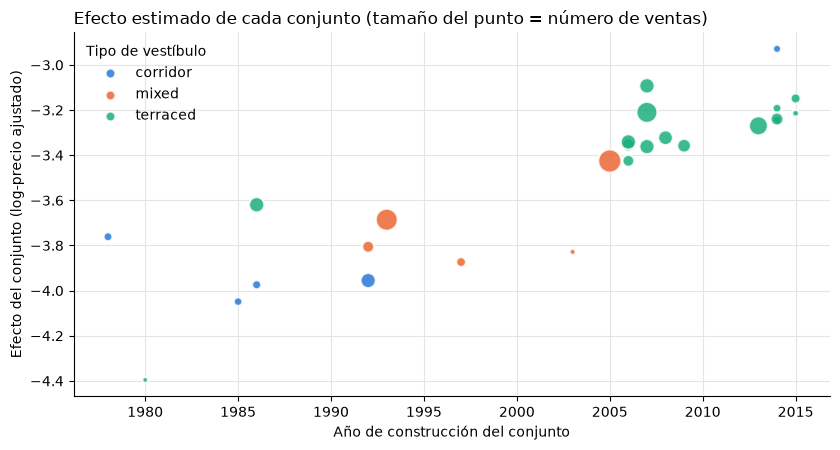

In [16]:
modelo_efectos = ajustar("logPrice ~ 0 + C(complejo) + " + base_vivienda, robusto=False)
efectos = modelo_efectos.params.filter(like="C(complejo)")
efectos.index = [int(nombre.split("[")[1].rstrip("]")) for nombre in efectos.index]
conjuntos = tabla_conjuntos.copy()
conjuntos["efecto"] = efectos
conjuntos["ventas"] = train.groupby("complejo").size()
conjuntos["Antiguedad"] = 2012 - conjuntos["YearBuilt"]  # antiguedad en un año de referencia

r2_antiguedad = smf.wls("efecto ~ Antiguedad", conjuntos, weights=conjuntos["ventas"]).fit().rsquared
print(f"R2 (ponderado) del efecto del conjunto sobre la antiguedad: {r2_antiguedad:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for tipo, color in zip(["corridor", "mixed", "terraced"], [AZUL, NARANJA, AGUA]):
    grupo = conjuntos[conjuntos["HallwayType"] == tipo]
    ax.scatter(grupo["YearBuilt"], grupo["efecto"], s=grupo["ventas"] / 2 + 15, color=color, alpha=0.85,
               edgecolors="white", linewidth=1.5, label=tipo)
ax.set_xlabel("Año de construcción del conjunto")
ax.set_ylabel("Efecto del conjunto (log-precio ajustado)")
ax.set_title("Efecto estimado de cada conjunto (tamaño del punto = número de ventas)", loc="left")
leyenda = ax.legend(title="Tipo de vestíbulo", frameon=False)
for marca in leyenda.legend_handles:
    marca.set_sizes([50])
estilo(ax)
plt.tight_layout()
plt.show()

In [17]:
grupos_nivel2 = dict(grupos_conjunto)


def ajustar_nivel2(variables):
    formula = "efecto ~ 1" + "".join(" + " + grupos_nivel2[v] for v in variables)
    return smf.wls(formula, conjuntos, weights=conjuntos["ventas"]).fit()


def criterios_nivel2(variables):
    modelo = ajustar_nivel2(variables)
    X2 = modelo.model.exog
    p = np.linalg.matrix_rank(X2)
    m = len(conjuntos)
    if p < X2.shape[1] or p >= m - 2:
        return None  # modelo no identificable o sin grados de libertad
    Xw = X2 * np.sqrt(conjuntos["ventas"].to_numpy())[:, None]
    h = np.einsum("ij,ji->i", Xw, np.linalg.pinv(Xw.T @ Xw) @ Xw.T)
    loo = np.inf if (h > 0.999).any() else np.sqrt(np.average((modelo.resid / (1 - h)) ** 2, weights=conjuntos["ventas"]))
    k = p + 1
    return {"variables": ", ".join(variables), "k": len(variables), "p": p, "R2": modelo.rsquared,
            "AICc": modelo.aic + 2 * k * (k + 1) / (m - k - 1), "BIC": modelo.bic, "RMSE LOO": loo}


filas = [criterios_nivel2(list(S)) for k in range(6) for S in combinations(grupos_nivel2, k)]
nivel2 = pd.DataFrame([f for f in filas if f is not None])
print("Modelos evaluados:", len(nivel2))
for criterio in ["AICc", "BIC", "RMSE LOO"]:
    print(f"\nCinco mejores segun {criterio}:")
    display(nivel2.nsmallest(5, criterio).round(3).set_index("variables"))
print("\nMejor modelo de cada tamaño segun RMSE LOO:")
nivel2.loc[nivel2.groupby("k")["RMSE LOO"].idxmin()].round(3).set_index("k")

Modelos evaluados: 4865

Cinco mejores segun AICc:


,k,p,R2,AICc,BIC,RMSE LOO
variables,,,,,,
"Antiguedad, N_manager, N_SchoolNearBy_Total",3,4,0.860,-25.410,-23.377,0.116
"Antiguedad, N_Parkinglot_Basement, N_SchoolNearBy_Total",3,4,0.859,-25.123,-23.090,0.111
"Antiguedad, HeatingType, N_Parkinglot_Basement, N_SchoolNearBy_Total",4,5,0.873,-24.380,-22.511,inf
"Antiguedad, HeatingType, N_Parkinglot_Basement, N_FacilitiesNearBy_Total",4,5,0.871,-24.009,-22.140,inf
"Antiguedad, HeatingType, N_Parkinglot_Basement, N_APT, N_FacilitiesNearBy_Total",5,6,0.887,-23.632,-22.305,inf



Cinco mejores segun BIC:


,k,p,R2,AICc,BIC,RMSE LOO
variables,,,,,,
"Antiguedad, N_manager, N_SchoolNearBy_Total",3,4,0.860,-25.410,-23.377,0.116
"Antiguedad, N_Parkinglot_Basement, N_SchoolNearBy_Total",3,4,0.859,-25.123,-23.090,0.111
"Antiguedad, HeatingType, N_Parkinglot_Basement, N_SchoolNearBy_Total",4,5,0.873,-24.380,-22.511,inf
"Antiguedad, HeatingType, N_Parkinglot_Basement, N_APT, N_FacilitiesNearBy_Total",5,6,0.887,-23.632,-22.305,inf
"Antiguedad, HeatingType, N_Parkinglot_Basement, N_FacilitiesNearBy_Total",4,5,0.871,-24.009,-22.140,inf



Cinco mejores segun RMSE LOO:


,k,p,R2,AICc,BIC,RMSE LOO
variables,,,,,,
"Antiguedad, N_Parkinglot_Basement, N_SchoolNearBy_Total",3,4,0.859,-25.123,-23.090,0.111
"Antiguedad, N_Parkinglot_Basement, N_FacilitiesInApt, N_SchoolNearBy_Total",4,5,0.863,-22.533,-20.663,0.113
"Antiguedad, N_Parkinglot_Ground, N_Parkinglot_Basement, N_SchoolNearBy_Total",4,5,0.863,-22.434,-20.565,0.114
"Antiguedad, N_APT, N_manager, N_FacilitiesInApt, N_SchoolNearBy_Total",5,6,0.870,-19.988,-18.662,0.116
"Antiguedad, N_manager, N_SchoolNearBy_Total",3,4,0.860,-25.410,-23.377,0.116



Mejor modelo de cada tamaño segun RMSE LOO:


,variables,p,R2,AICc,BIC,RMSE LOO
k,,,,,,
0,,1,0.000,17.321,18.057,0.261
1,Antiguedad,2,0.737,-14.830,-13.404,0.144
2,"Antiguedad, N_manager",3,0.782,-16.912,-15.042,0.133
3,"Antiguedad, N_Parkinglot_Basement, N_SchoolNearBy_Total",4,0.859,-25.123,-23.090,0.111
4,"Antiguedad, N_Parkinglot_Basement, N_FacilitiesInApt, N_SchoolNearBy_Total",5,0.863,-22.533,-20.663,0.113
5,"Antiguedad, N_APT, N_manager, N_FacilitiesInApt, N_SchoolNearBy_Total",6,0.870,-19.988,-18.662,0.116


In [18]:
# Seleccion por pasos con pruebas F en el nivel conjunto (entra si p < 0,05; sale si p > 0,10)
def identificable(modelo):
    return np.linalg.matrix_rank(modelo.model.exog) == modelo.model.exog.shape[1] and modelo.df_resid >= 3


seleccion2, pasos = [], []
while True:
    candidatos = []
    for v in grupos_nivel2:
        if v in seleccion2:
            continue
        nuevo = ajustar_nivel2(seleccion2 + [v])
        if identificable(nuevo):
            F, p, _ = nuevo.compare_f_test(ajustar_nivel2(seleccion2))
            candidatos.append((p, v, F))
    p, v, F = min(candidatos)
    if p >= 0.05:
        pasos.append(f"se detiene: la mejor candidata ({v}) tiene p = {p:.3f}")
        break
    seleccion2.append(v)
    pasos.append(f"entra {v} (F = {F:.1f}, p = {p:.4f})")
    actual = ajustar_nivel2(seleccion2)
    for w in list(seleccion2):
        p_sale = actual.compare_f_test(ajustar_nivel2([u for u in seleccion2 if u != w]))[1]
        if p_sale > 0.10:
            seleccion2.remove(w)
            pasos.append(f"sale {w} (p = {p_sale:.3f})")
print("Hacia adelante:", "; ".join(pasos))

# Eliminacion hacia atras desde las variables numericas y binarias (las de mas de dos niveles agotan los gl)
atras = ["Antiguedad", "HallwayType", "AptManageType", "N_Parkinglot_Ground", "N_Parkinglot_Basement", "N_APT",
         "N_manager", "N_elevators", "N_FacilitiesInApt", "N_FacilitiesNearBy_Total", "N_SchoolNearBy_Total"]
pasos = []
while True:
    actual = ajustar_nivel2(atras)
    valores_p = {v: actual.compare_f_test(ajustar_nivel2([u for u in atras if u != v]))[1] for v in atras}
    peor = max(valores_p, key=valores_p.get)
    if valores_p[peor] < 0.05:
        break
    atras.remove(peor)
    pasos.append(f"{peor} (p = {valores_p[peor]:.3f})")
print("Hacia atras, salen en orden:", "; ".join(pasos))
print("Hacia atras, quedan:", ", ".join(atras))

# LASSO en el nivel conjunto con validacion dejando uno por fuera
X2 = dmatrix(" + ".join(grupos_nivel2.values()), conjuntos, return_type="dataframe").drop(columns="Intercept")
lasso2 = LassoCV(cv=LeaveOneOut(), alphas=np.logspace(-4, 0, 60), max_iter=100000).fit(
    StandardScaler().fit_transform(X2), conjuntos["efecto"], sample_weight=conjuntos["ventas"])
coef2 = pd.Series(lasso2.coef_, index=X2.columns)
print(f"\nLASSO nivel conjunto (alpha = {lasso2.alpha_:.4f}), coeficientes estandarizados distintos de cero:")
coef2[coef2.abs() > 1e-8].sort_values(key=abs, ascending=False).round(4).to_frame("Coeficiente")

Hacia adelante: entra Antiguedad (F = 67.2, p = 0.0000); entra HeatingType (F = 6.3, p = 0.0196); se detiene: la mejor candidata (N_manager) tiene p = 0.068
Hacia atras, salen en orden: N_FacilitiesNearBy_Total (p = 0.964); N_Parkinglot_Ground (p = 0.798); N_Parkinglot_Basement (p = 0.621); AptManageType (p = 0.400); HallwayType (p = 0.162); N_elevators (p = 0.225); N_APT (p = 0.340); N_FacilitiesInApt (p = 0.496)
Hacia atras, quedan: Antiguedad, N_manager, N_SchoolNearBy_Total

LASSO nivel conjunto (alpha = 0.0173), coeficientes estandarizados distintos de cero:


,Coeficiente
Antiguedad,-0.1630
N_Parkinglot_Basement,0.0355
C(HallwayType)[T.terraced],0.0337
N_FacilitiesNearBy_Total,-0.0290
C(SubwayStation)[T.Banwoldang],0.0174
C(TimeToBusStop)[T.5min~10min],-0.0169
N_manager,0.0153
C(SubwayStation)[T.Myung-duk],-0.0147
N_SchoolNearBy_Total,-0.0094


**Interpretación**

* **La antigüedad domina.** Sola explica el 73,7 % de la variación (ponderada) del efecto de conjunto.
  El gráfico muestra que los conjuntos más nuevos tienen efectos mayores. El tipo de vestíbulo acompaña
  a la antigüedad: la mayoría de los conjuntos posteriores a 2005 son *terraced*, por eso el vestíbulo
  aporta poco una vez se controla la antigüedad.
* **Con n = 26 los criterios eligen modelos de tres variables:** antigüedad, una variable de escala y una de entorno.
  * El mejor por RMSE LOO es antigüedad + parqueaderos en sótano + escuelas cercanas (0,111, $R^2$ = 0,859).
  * El mejor por AICc y BIC es antigüedad + administradores + escuelas cercanas. La diferencia de AICc entre
    ambos es de 0,3 puntos, lo que equivale a un empate. Parqueaderos y administradores pertenecen al mismo
    bloque redundante (r = 0,74) y los datos no distinguen entre ellos.
* **Selección por pasos.** La eliminación hacia atrás termina en antigüedad + administradores + escuelas cercanas.
  La selección hacia adelante agrega la calefacción después de la antigüedad (p = 0,020), pero la calefacción
  central corresponde a un único conjunto (el 3, con 212 ventas). Su coeficiente es la desviación propia de ese
  conjunto y no un efecto generalizable, por ese mismo motivo, el error LOO de cualquier modelo con calefacción
  es infinito: ese conjunto tiene apalancamiento 1.
* **LASSO (LOO).** Concentra casi todo el peso en la antigüedad (−0,163 en escala estandarizada).
  Le siguen con coeficientes al menos cuatro veces menores, los parqueaderos, el vestíbulo *terraced*
  y las instalaciones cercanas.

**Resultado.** Tienen respaldo en el nivel donde varían la antigüedad, una variable de escala (parqueaderos en
sótano o administradores) y una de entorno (escuelas cercanas). La sección 2.7 elige entre las alternativas de
escala y entorno usando el modelo de viviendas.

### 2.7 Comparación de las combinaciones finalistas en el modelo de viviendas

In [19]:
def rmse_cv(formula, particion, datos=None):
    datos = train if datos is None else datos
    errores = []
    for ajuste, valida in particion.split(datos, groups=datos["complejo"]):
        modelo = smf.ols(formula, datos.iloc[ajuste]).fit()
        errores.append((datos["logPrice"].iloc[valida] - modelo.predict(datos.iloc[valida])) ** 2)
    return float(np.sqrt(pd.concat(errores).mean()))


base_seleccion = base_vivienda + " + Antiguedad"
filas = []
for escala, entorno in product(["N_Parkinglot_Basement", "N_manager", "N_FacilitiesInApt"],
                               ["N_SchoolNearBy_Total", "N_FacilitiesNearBy_Total"]):
    formula = f"logPrice ~ {base_seleccion} + {escala} + {entorno}"
    modelo = ajustar(formula)
    filas.append({"Escala": escala, "Entorno": entorno, "R2 ajustado": modelo.rsquared_adj,
                  "AIC": modelo.aic, "BIC": modelo.bic,
                  "RMSE VC-10": rmse_cv(formula, kfold), "RMSE VC-conjunto": rmse_cv(formula, por_conjunto),
                  "t Antiguedad": modelo.tvalues["Antiguedad"], "t escala": modelo.tvalues[escala],
                  "t entorno": modelo.tvalues[entorno]})
finalistas = pd.DataFrame(filas).sort_values("BIC")
print("t con errores estandar agrupados por conjunto")
finalistas.round(4)

t con errores estandar agrupados por conjunto


,Escala,Entorno,R2 ajustado,AIC,BIC,RMSE VC-10,RMSE VC-conjunto,t Antiguedad,t escala,t entorno
0,N_Parkinglot_Basement,N_SchoolNearBy_Total,0.9366,-4560.9693,-4440.8024,0.1394,0.1679,-5.3096,4.3443,-3.2225
2,N_manager,N_SchoolNearBy_Total,0.9362,-4539.1150,-4418.9480,0.1398,0.1734,-9.2793,4.2968,-3.4478
1,N_Parkinglot_Basement,N_FacilitiesNearBy_Total,0.9353,-4481.9337,-4361.7667,0.1407,0.1738,-4.8392,4.8864,-3.3233
3,N_manager,N_FacilitiesNearBy_Total,0.9351,-4468.9530,-4348.7860,0.1409,0.1791,-7.5297,3.5060,-2.8621
4,N_FacilitiesInApt,N_SchoolNearBy_Total,0.9320,-4273.5627,-4153.3957,0.1444,0.1749,-6.5512,3.1554,-2.3922
5,N_FacilitiesInApt,N_FacilitiesNearBy_Total,0.9313,-4234.5967,-4114.4297,0.1450,0.1779,-5.4483,2.8145,-2.6160


**Interpretación.** En las seis combinaciones de un representante de escala y uno de entorno, junto con la
antigüedad, los tres coeficientes son claramente distintos de cero con errores agrupados (|t| ≥ 2,39).
La combinación **antigüedad + parqueaderos en sótano + escuelas cercanas** es la mejor en los cuatro criterios:

| Criterio | Antigüedad + parqueaderos + escuelas | Antigüedad + administradores + escuelas |
|---|---|---|
| AIC | −4.561 | −4.539 |
| BIC | −4.441 | −4.419 |
| RMSE VC-10 | 0,1394 | 0,1398 |
| RMSE VC-conjunto | 0,1679 | 0,1734 |

Es también la mejor por LOO en el nivel conjunto (2.6), además los parqueaderos en sótano son un atributo
concreto que el comprador observa y valora, mientras que el número de administradores es un indicador
indirecto del tamaño del conjunto. Se eligen entonces los **parqueaderos en sótano** como representante
de la escala y las **escuelas cercanas** como representante del entorno.

### 2.8 Contraste: ¿aportan las variables excluidas?

Cada variable excluida se agrega, una a la vez, al modelo con las variables seleccionadas.
Se compara la prueba F clásica (que supone ventas independientes) con la prueba de Wald con errores
estándar agrupados por conjunto y se reportan los cambios en AIC, BIC y en los errores de validación.

In [20]:
def prueba_termino(modelo, termino):
    """Prueba F (Wald) de que todos los coeficientes de un termino del modelo son cero."""
    cortes = modelo.model.data.model_spec.term_name_slices
    columnas = list(range(len(modelo.params)))[cortes[termino]]
    R = np.eye(len(modelo.params))[columnas]
    prueba = modelo.wald_test(R, use_f=True, scalar=True)
    return float(prueba.statistic), float(prueba.pvalue), len(columnas)


seleccionadas = ["Antiguedad", "N_Parkinglot_Basement", "N_SchoolNearBy_Total"]
formula_seleccion = "logPrice ~ " + base_vivienda + "".join(" + " + v for v in seleccionadas)
clasico_sel = ajustar(formula_seleccion, robusto=False)
vc10_sel, vcc_sel = rmse_cv(formula_seleccion, kfold), rmse_cv(formula_seleccion, por_conjunto)
print(f"Modelo seleccionado: RMSE VC-10 = {vc10_sel:.4f}, RMSE VC-conjunto = {vcc_sel:.4f}")
print("Cada fila agrega una variable al modelo seleccionado; VC-conjunto es el RMSE del modelo ampliado")

filas = []
for nombre, termino in grupos_conjunto.items():
    if nombre in seleccionadas:
        continue
    formula = formula_seleccion + " + " + termino
    clasico, agrupado = ajustar(formula, robusto=False), ajustar(formula)
    F_c, p_c, gl = prueba_termino(clasico, termino)
    F_a, p_a, _ = prueba_termino(agrupado, termino)
    p_n2 = ajustar_nivel2(seleccionadas + [nombre]).compare_f_test(ajustar_nivel2(seleccionadas))[1]
    filas.append({"Variable": nombre, "gl": gl, "Conjuntos por nivel": "",
                  "p F clasica": p_c, "p Wald agrupada": p_a, "p F nivel conjunto (n = 26)": p_n2,
                  "Cambio AIC": clasico.aic - clasico_sel.aic, "Cambio BIC": clasico.bic - clasico_sel.bic,
                  "Cambio VC-10": rmse_cv(formula, kfold) - vc10_sel,
                  "VC-conjunto": formato_error(rmse_cv(formula, por_conjunto))})
excluidas = pd.DataFrame(filas).set_index("Variable")

# Para las categoricas: cuantos conjuntos sostienen cada nivel
for col in categoricas:
    if col in excluidas.index:
        conteo = tabla_conjuntos[col].value_counts()
        excluidas.loc[col, "Conjuntos por nivel"] = ", ".join(f"{k}: {v}" for k, v in conteo[conteo > 0].items())
excluidas.sort_values("p F nivel conjunto (n = 26)").round(4)

Modelo seleccionado: RMSE VC-10 = 0.1394, RMSE VC-conjunto = 0.1679
Cada fila agrega una variable al modelo seleccionado; VC-conjunto es el RMSE del modelo ampliado


,gl,Conjuntos por nivel,p F clasica,p Wald agrupada,p F nivel conjunto (n = 26),Cambio AIC,Cambio BIC,Cambio VC-10,VC-conjunto
Variable,,,,,,,,,
HeatingType,1,"individual_heating: 25, central_heating: 1",0.0000,0.0330,0.1460,-202.6162,-196.2916,-0.0034,0.1703
SubwayStation,7,"Myung-duk: 6, Kyungbuk_uni_hospital: 5, Banwoldang: 4, Sin-nam: 3, no_subway_nearby: 3, Chil-sung-market: 2, Daegu: ...",0.0000,0.0000,0.1461,-756.8138,-712.5418,-0.0122,2.0e+07 (explota)
N_manager,1,,0.0000,0.4347,0.2865,-45.4499,-39.1253,-0.0007,0.1764
TimeToBusStop,2,"0~5min: 17, 5min~10min: 8, 10min~15min: 1",0.0000,0.0202,0.3030,-202.3555,-189.7064,-0.0033,0.1661
N_FacilitiesNearBy_Total,1,,0.0000,0.3639,0.3660,-74.5164,-68.1918,-0.0012,0.1742
N_FacilitiesInApt,1,,0.0014,0.6095,0.4181,-8.2709,-1.9463,-0.0001,0.1713
N_Parkinglot_Ground,1,,0.0000,0.5669,0.4472,-20.6975,-14.3729,-0.0003,0.1719
HallwayType,2,"terraced: 15, corridor: 6, mixed: 5",0.0000,0.1329,0.4787,-209.3475,-196.6983,-0.0034,0.1743
N_APT,1,,0.0000,0.3878,0.6496,-44.0172,-37.6926,-0.0007,0.1721


**Interpretación.** La tabla muestra por qué la regla de decisión debe tener en cuenta el nivel de la información:

* **Prueba F clásica.** Trata las 4.124 ventas como independientes, con ella, 10 de las 12 variables
  excluidas resultan significativas (p < 0,01) y 11 reducen el AIC. Con esta prueba el modelo terminaría
  saturado de variables de conjunto.
* **Prueba de Wald con errores agrupados.** Descarta la mayoría. Solo la estación, la parada de bus y
  la calefacción quedan con p < 0,05, y en las tres el respaldo es débil:
  * La calefacción central es un solo conjunto.
  * El nivel de 10 a 15 minutos a la parada de bus es un solo conjunto.
  * La estación usa 7 grados de libertad para 26 conjuntos, y Bangoge es un único conjunto.

  Con pocos conglomerados y contrastes de varios grados de libertad, esta prueba tiende a rechazar
  más de lo que debería.
* **Prueba F en el nivel conjunto (n = 26).** Ninguna variable excluida aporta información sobre el efecto
  de conjunto una vez incluidas la antigüedad, los parqueaderos y las escuelas (todos los p > 0,14).
* **Validación cruzada.** La estación mejora la VC-10 porque ayuda a identificar el conjunto, pero hace
  explotar la VC-conjunto. La parada de bus apenas cambia los errores.

**Regla aplicada.** Una variable de conjunto entra solo si tiene respaldo en el nivel donde varía
(prueba F con n = 26). Ninguna de las excluidas lo tiene.

### 2.9 Síntesis de la selección

In [21]:
mejor_bic = subconjuntos.loc[subconjuntos["BIC"].idxmin(), "variables"]
mejor_loo = nivel2.loc[nivel2["RMSE LOO"].idxmin(), "variables"].split(", ")
mejor_aicc = nivel2.loc[nivel2["AICc"].idxmin(), "variables"].split(", ")
metodos = {
    "Mejores subconjuntos, BIC (viviendas)": mejor_bic,
    "Hacia adelante, AIC (viviendas)": seleccion,
    "LASSO VC-10 (viviendas)": seleccion_lasso["VC-10"],
    "LASSO VC-conjunto (viviendas)": seleccion_lasso["VC-conjunto"],
    "Mejores subconjuntos, LOO (conjuntos)": mejor_loo,
    "Mejores subconjuntos, AICc (conjuntos)": mejor_aicc,
    "Hacia adelante, F (conjuntos)": seleccion2,
    "Hacia atras, F (conjuntos)": atras,
    "LASSO LOO (conjuntos)": [g for g, t in grupos_conjunto.items()
                              if any(c == t or c.startswith(t + "[") for c in coef2[coef2.abs() > 1e-8].index)],
}
sintesis = pd.DataFrame({m: ["✓" if g in v else "" for g in grupos_conjunto] for m, v in metodos.items()},
                        index=list(grupos_conjunto))
sintesis["Votos, métodos de viviendas (4)"] = (sintesis.iloc[:, 0:4] == "✓").sum(axis=1)
sintesis["Votos, métodos de conjuntos (5)"] = (sintesis.iloc[:, 4:9] == "✓").sum(axis=1)
sintesis.sort_values(["Votos, métodos de conjuntos (5)", "Votos, métodos de viviendas (4)"], ascending=False)

,"Mejores subconjuntos, BIC (viviendas)","Hacia adelante, AIC (viviendas)",LASSO VC-10 (viviendas),LASSO VC-conjunto (viviendas),"Mejores subconjuntos, LOO (conjuntos)","Mejores subconjuntos, AICc (conjuntos)","Hacia adelante, F (conjuntos)","Hacia atras, F (conjuntos)",LASSO LOO (conjuntos),"Votos, métodos de viviendas (4)","Votos, métodos de conjuntos (5)"
Antiguedad,✓,✓,✓,✓,✓,✓,✓,✓,✓,4,5
N_SchoolNearBy_Total,,,✓,,✓,✓,,✓,✓,1,4
N_manager,✓,✓,✓,,,✓,,✓,✓,3,3
N_Parkinglot_Basement,✓,✓,✓,✓,✓,,,,✓,4,2
HallwayType,✓,✓,✓,✓,,,,,✓,4,1
SubwayStation,✓,✓,✓,✓,,,,,✓,4,1
N_FacilitiesNearBy_Total,✓,✓,✓,✓,,,,,✓,4,1
HeatingType,✓,✓,✓,,,,✓,,,3,1
TimeToBusStop,✓,✓,✓,,,,,,✓,3,1
TimeToSubway,✓,✓,✓,✓,,,,,,4,0


**Variables seleccionadas.** Los cuatro métodos que tratan las ventas como independientes votan por casi
todas las variables (sección 2.5). En los cinco métodos aplicados en el nivel conjunto, el consenso es claro:

* La **antigüedad** aparece en los cinco.
* Las **escuelas cercanas** aparecen en cuatro.
* Para la escala **administradores** (3 votos) y **parqueaderos en sótano** (2 votos) son sustitutos cercanos. Se eligen los parqueaderos por su mejor desempeño en el modelo de viviendas (sección 2.7).
* Ninguna otra variable obtiene más de un voto.

| Variable | Rol | Justificación |
|---|---|---|
| `SalePrice` (en log) | Respuesta | Es la variable que el gerente quiere predecir. La escala se evalúa en 3.1. |
| `Size_sqf` | Vivienda | Mayor asociación con el precio (r = 0,70). Varía dentro de 25 de los 26 conjuntos. |
| `Floor` | Vivienda | Varía dentro de todos los conjuntos. Asociación positiva con el precio. |
| `YrSold`, `MonthSold` | Momento de la venta | Los precios cambian en el tiempo. La forma se evalúa en 3.3. |
| `Bloque` (derivada) | Tipo de venta | Identifica las dos ventas masivas con descuento (2.3). |
| `Antiguedad` | Conjunto (y venta, vía el año) | Seleccionada por los nueve métodos. Explica el 74 % de la variación entre conjuntos. |
| `N_Parkinglot_Basement` | Conjunto: escala y dotaciones | Representa el bloque de parqueaderos, apartamentos, administradores, ascensores e instalaciones. |
| `N_SchoolNearBy_Total` | Conjunto: entorno | Representa el bloque de escuelas e instalaciones cercanas. |

**Excluidas.** Tipo de vestíbulo, calefacción, tipo de administración, tiempo al metro, tiempo al bus,
estación, parqueaderos en superficie, número de apartamentos, administradores, ascensores,
instalaciones del conjunto y total de instalaciones cercanas, por redundancia con las seleccionadas o
por falta de respaldo en el nivel conjunto. También los 10 componentes de servicios cercanos,
por dependencia exacta con los totales.

## 3. Determinación de la estructura del modelo

Con las variables seleccionadas se decide cómo entran al modelo: la escala de la respuesta, la forma
funcional de las variables numéricas, la codificación del tiempo y de las indicadoras, las interacciones,
el centrado de las variables y la estructura del término de error. Cada decisión se contrasta con
pruebas sobre los coeficientes (errores agrupados por conjunto), criterios de información y error de
validación cruzada.

### 3.1 Transformación de la variable respuesta (Box-Cox)

In [22]:
def perfil_boxcox(formula_x, lambdas=np.linspace(-0.3, 1.1, 57)):
    """SSE de la respuesta Box-Cox normalizada (divide por la media geometrica) para cada lambda."""
    X = dmatrix(formula_x, train, return_type="dataframe").to_numpy()
    precio = train["SalePrice"].to_numpy(dtype=float)
    media_geo = np.exp(np.log(precio).mean())

    def sse(lam):
        z = media_geo * np.log(precio) if abs(lam) < 1e-9 else (precio ** lam - 1) / (lam * media_geo ** (lam - 1))
        return sm.OLS(z, X).fit().ssr

    lam_opt = minimize_scalar(sse, bounds=(-1, 1.5), method="bounded").x
    sse_opt = sse(lam_opt)
    # Intervalo de confianza del 95 %: lambdas con n*log(SSE/SSE_min) <= 3,84
    lr = np.array([n * np.log(sse(l) / sse_opt) for l in lambdas])
    dentro = lambdas[lr <= 3.84]
    return lam_opt, (dentro.min(), dentro.max()) if len(dentro) else (np.nan, np.nan), lambdas, lr, n * np.log(sse(0) / sse_opt)


especificaciones = {
    "Vivienda y tiempo, sin Bloque": "logSize + I(logSize ** 2) + Floor + C(YrSold) + MonthSold",
    "Seleccionadas, sin Bloque": "logSize + I(logSize ** 2) + Floor + C(YrSold) + MonthSold + Antiguedad"
                                 " + N_Parkinglot_Basement + N_SchoolNearBy_Total",
    "Seleccionadas, con Bloque": base_vivienda + " + Antiguedad + N_Parkinglot_Basement + N_SchoolNearBy_Total",
}
filas, perfiles = [], {}
for nombre, fx in especificaciones.items():
    lam, ic, grid, lr, lr_log = perfil_boxcox(fx)
    perfiles[nombre] = (grid, lr)
    filas.append({"Especificacion": nombre, "lambda estimado": lam, "IC 95 % inferior": ic[0],
                  "IC 95 % superior": ic[1], "Estadistico RV para lambda = 0 (log)": lr_log})
pd.DataFrame(filas).set_index("Especificacion").round(3)

,lambda estimado,IC 95 % inferior,IC 95 % superior,Estadistico RV para lambda = 0 (log)
Especificacion,,,,
"Vivienda y tiempo, sin Bloque",0.382,0.350,0.400,368.562
"Seleccionadas, sin Bloque",0.300,0.275,0.325,420.723
"Seleccionadas, con Bloque",0.295,0.275,0.300,565.901


,Breusch-Pagan,Asimetria residuos,Curtosis exceso,"Corr(|residuo|, ajustado)",RMSE VC-10 (USD)
Respuesta,,,,,
Nivel (lambda = 1),876.799,0.386,1.847,0.134,32848.778
Box-Cox (lambda = 0.29),479.548,-0.141,1.803,0.032,29488.958
Logaritmo (lambda = 0),525.131,-0.409,1.840,-0.100,33092.581


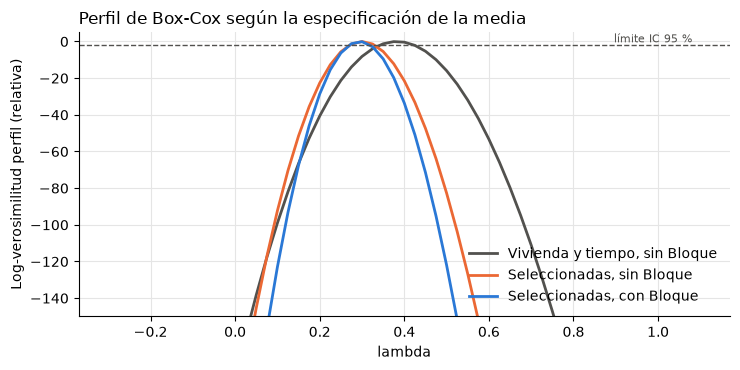

In [23]:
def comparar_respuestas(formula_x):
    """Diagnosticos de residuos y RMSE de validacion (en dolares) con la respuesta en nivel, Box-Cox y log."""
    X_bc = dmatrix(formula_x, train, return_type="dataframe")
    lam = perfil_boxcox(formula_x)[0]
    precio = train["SalePrice"].astype(float)
    respuestas = {
        "Nivel (lambda = 1)": (precio, lambda z: z),
        f"Box-Cox (lambda = {lam:.2f})": ((precio ** lam - 1) / lam,
                                          lambda z: np.clip(lam * z + 1, 1e-9, None) ** (1 / lam)),
        "Logaritmo (lambda = 0)": (np.log(precio), np.exp),
    }
    filas = []
    for nombre, (respuesta, inversa) in respuestas.items():
        modelo = sm.OLS(respuesta, X_bc).fit()
        estandarizados = modelo.resid / np.sqrt(modelo.mse_resid)
        errores = []
        for ajuste, valida in kfold.split(X_bc):
            parcial = sm.OLS(respuesta.iloc[ajuste], X_bc.iloc[ajuste]).fit()
            errores.append((precio.iloc[valida] - inversa(parcial.predict(X_bc.iloc[valida]))) ** 2)
        filas.append({"Respuesta": nombre,
                      "Breusch-Pagan": het_breuschpagan(modelo.resid, X_bc)[0],
                      "Asimetria residuos": estandarizados.skew(), "Curtosis exceso": estandarizados.kurt(),
                      "Corr(|residuo|, ajustado)": np.corrcoef(np.abs(estandarizados), modelo.fittedvalues)[0, 1],
                      "RMSE VC-10 (USD)": float(np.sqrt(pd.concat(errores).mean()))})
    return pd.DataFrame(filas).set_index("Respuesta")


display(comparar_respuestas(especificaciones["Seleccionadas, con Bloque"]).round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for (nombre, (grid, lr)), color in zip(perfiles.items(), [TINTA_2, NARANJA, AZUL]):
    ax.plot(grid, -lr / 2, color=color, linewidth=2, label=nombre)
ax.axhline(-3.84 / 2, color=TINTA_2, linewidth=1, linestyle="--")
ax.text(1.08, -3.84 / 2, "límite IC 95 %", ha="right", va="bottom", fontsize=8, color=TINTA_2)
ax.set_ylim(-150, 5)
ax.set_xlabel("lambda")
ax.set_ylabel("Log-verosimilitud perfil (relativa)")
ax.set_title("Perfil de Box-Cox según la especificación de la media", loc="left")
ax.legend(frameon=False, loc="lower right")
estilo(ax)
plt.tight_layout()
plt.show()

**Interpretación.** La transformación de Box-Cox $y^{(\lambda)} = (y^\lambda - 1)/\lambda$ incluye el nivel
($\lambda = 1$) y el logaritmo ($\lambda = 0$) como casos particulares. El $\lambda$ de máxima verosimilitud
depende de la especificación de la media:

* 0,38 solo con vivienda y tiempo.
* 0,30 al agregar las variables seleccionadas.
* 0,19 con la estructura final (sección 3.7).

Parte de lo que parecía exigir una transformación era una media mal especificada.

* **La escala original queda descartada en todos los casos:** su intervalo está lejos de $\lambda = 1$
  y es la escala con más heterocedasticidad (Breusch-Pagan = 877).
* **El logaritmo tampoco queda dentro del intervalo del 95 %**, pero con $n$ = 4.124 el intervalo es muy
  estrecho y rechaza cualquier valor redondo.

**Decisión: respuesta en logaritmo.**

* **Diagnósticos.** Las diferencias con el $\hat\lambda$ son moderadas y no van todas en la misma dirección.
  Con la estructura final, el log tiene menor heterocedasticidad (Breusch-Pagan 283 frente a 315) y el
  $\hat\lambda$ tiene residuos algo más simétricos.
* **Interpretación.** El log permite leer cada coeficiente como un cambio porcentual del precio.
  Una potencia de 0,19 no tiene una lectura directa.
* **Precisión.** El costo en predicción es bajo: con la estructura final, el RMSE en dólares del log es
  un 4 % mayor que el de Box-Cox (sección 3.7). Para la competencia también se evalúa Box-Cox (sección 4).

### 3.2 Forma funcional de las variables numéricas

In [24]:
resto_tamano = "Floor + C(YrSold) + MonthSold + Bloque + Antiguedad + N_Parkinglot_Basement + N_SchoolNearBy_Total"
formas = {
    "Tamaño": [("Size_sqf", f"Size_sqf + {resto_tamano}"),
               ("log(Size)", f"logSize + {resto_tamano}"),
               ("Size + Size²", f"Size_sqf + I(Size_sqf ** 2) + {resto_tamano}"),
               ("log(Size) + log(Size)²", f"logSize + I(logSize ** 2) + {resto_tamano}")],
}
resto_antig = "logSize + I(logSize ** 2) + Floor + C(YrSold) + MonthSold + Bloque + N_Parkinglot_Basement + N_SchoolNearBy_Total"
formas["Antigüedad"] = [("Antiguedad", f"Antiguedad + {resto_antig}"),
                        ("Antiguedad + Antiguedad²", f"Antiguedad + I(Antiguedad ** 2) + {resto_antig}")]
resto_piso = resto_antig.replace("Floor + ", "") + " + Antiguedad + I(Antiguedad ** 2)"
formas["Piso"] = [("Floor", f"Floor + {resto_piso}"),
                  ("log(Floor)", f"np.log(Floor) + {resto_piso}"),
                  ("Floor + Floor²", f"Floor + I(Floor ** 2) + {resto_piso}")]
filas = []
for variable, opciones in formas.items():
    for etiqueta, rhs in opciones:
        modelo = ajustar("logPrice ~ " + rhs)
        termino_cuad = {"Tamaño": "I(Size_sqf ** 2)" if "Size_sqf ** 2" in rhs else "I(logSize ** 2)",
                        "Antigüedad": "I(Antiguedad ** 2)", "Piso": "I(Floor ** 2)"}[variable]
        p_cuad = modelo.pvalues.get(termino_cuad, np.nan)
        filas.append({"Variable": variable, "Forma": etiqueta, "AIC": modelo.aic, "BIC": modelo.bic,
                      "p termino cuadratico (agrupado)": p_cuad,
                      "RMSE VC-10": rmse_cv("logPrice ~ " + rhs, kfold),
                      "RMSE VC-conjunto": rmse_cv("logPrice ~ " + rhs, por_conjunto)})
pd.DataFrame(filas).set_index(["Variable", "Forma"]).round(4)

AIC        BIC  p termino cuadratico (agrupado)  RMSE VC-10  RMSE VC-conjunto
Variable   Forma                                                                                                        
Tamaño     Size_sqf                 -1017.7192  -903.8768                              NaN      0.2141            0.2541
           log(Size)                -4136.2469 -4022.4045                              NaN      0.1467            0.1693
           Size + Size²             -4239.1573 -4118.9903                           0.0000      0.1450            0.1656
           log(Size) + log(Size)²   -4560.9693 -4440.8024                           0.0047      0.1394            0.1679
Antigüedad Antiguedad               -4560.9693 -4440.8024                              NaN      0.1394            0.1679
           Antiguedad + Antiguedad² -4956.0718 -4829.5802                           0.0006      0.1329            0.1614
Piso       Floor                    -4956.0718 -4829.5802                              NaN      0.1329            0.1614
           log(Floor)               -4973.6628 -4847.1712                              NaN      0.1326            0.1610
           Floor + Floor²           -4968.0603 -4835.2441                           0.0936      0.1327            0.1617

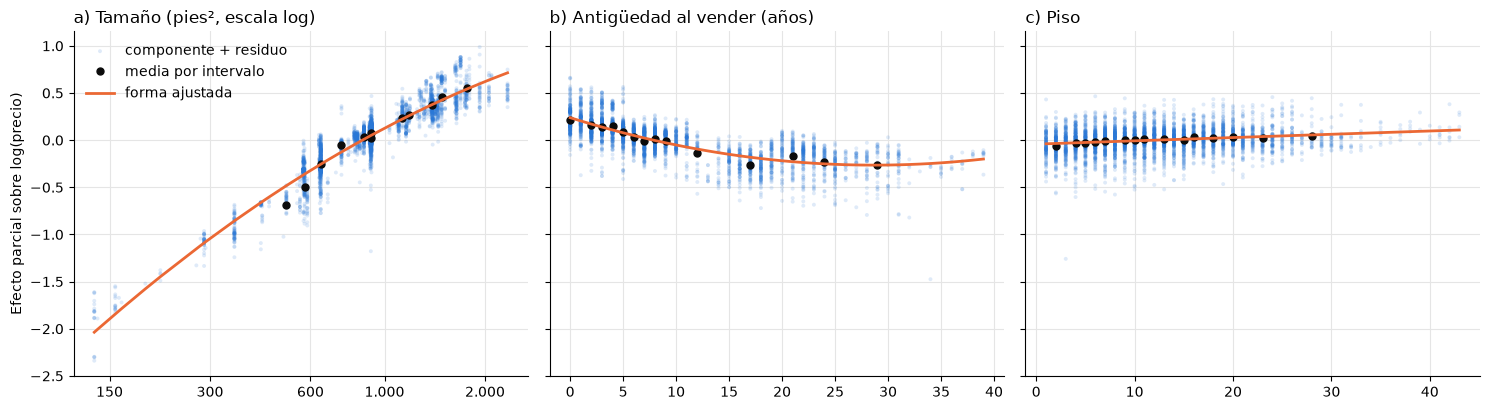

In [25]:
# Graficos de componente mas residuo: efecto parcial estimado + residuo, frente a cada variable
modelo_formas = ajustar("logPrice ~ logSize + I(logSize ** 2) + Floor + C(YrSold) + MonthSold + Bloque"
                        " + Antiguedad + I(Antiguedad ** 2) + N_Parkinglot_Basement + N_SchoolNearBy_Total")
b = modelo_formas.params
residuo = modelo_formas.resid
paneles = [
    ("Size_sqf", b["logSize"] * train["logSize"] + b["I(logSize ** 2)"] * train["logSize"] ** 2,
     "a) Tamaño (pies², escala log)", "Size_sqf"),
    ("Antiguedad", b["Antiguedad"] * train["Antiguedad"] + b["I(Antiguedad ** 2)"] * train["Antiguedad"] ** 2,
     "b) Antigüedad al vender (años)", "Antiguedad"),
    ("Floor", b["Floor"] * train["Floor"], "c) Piso", "Floor"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (col, componente, titulo, _) in zip(axes, paneles):
    x = train[col]
    parcial = componente - componente.mean() + residuo
    ax.scatter(x, parcial, s=8, color=AZUL, alpha=0.15, edgecolors="none", label="componente + residuo")
    medias = parcial.groupby(pd.qcut(x, 15, duplicates="drop"), observed=True).agg(["mean"]).assign(
        x=x.groupby(pd.qcut(x, 15, duplicates="drop"), observed=True).median())
    ax.plot(medias["x"], medias["mean"], color=TINTA, marker="o", markersize=5, linewidth=0, label="media por intervalo")
    orden = np.argsort(x.to_numpy())
    ax.plot(x.to_numpy()[orden], (componente - componente.mean()).to_numpy()[orden], color=NARANJA, linewidth=2,
            label="forma ajustada")
    ax.set_title(titulo, loc="left")
    estilo(ax)
axes[0].set_xscale("log")
axes[0].set_xticks([150, 300, 600, 1000, 2000], labels=["150", "300", "600", "1.000", "2.000"])
axes[0].minorticks_off()
axes[0].set_ylabel("Efecto parcial sobre log(precio)")
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación**

* **Tamaño.** El logaritmo del tamaño mejora mucho a la forma lineal (el AIC baja en 3.100 puntos y el
  RMSE VC-10 pasa de 0,214 a 0,147): el precio responde a cambios proporcionales del tamaño. Agregar el
  cuadrado del log da el mejor AIC, BIC y VC-10, y el término es significativo con errores agrupados
  (p = 0,005). En VC-conjunto la forma Size + Size² es apenas mejor (0,1656 frente a 0,1679).
  Se adopta $\log(\text{Size}) + \log(\text{Size})^2$, que permite que la elasticidad precio-tamaño disminuya
  con el tamaño (rendimientos decrecientes del espacio). En el gráfico (a), la curva ajustada sigue las medias
  por intervalo.
* **Antigüedad.** El término cuadrático es significativo (p < 0,001) y mejora AIC, BIC y las dos validaciones.
  La depreciación es convexa: fuerte en los primeros años y casi plana hacia los 25 a 30 años (gráfico b).
* **Piso.** El efecto es pequeño y casi lineal: el término cuadrático no es significativo (p = 0,094).
  El logaritmo del piso tiene un AIC algo menor, pero el error de validación es prácticamente el mismo
  (0,1326 frente a 0,1329). Se conserva la forma lineal, cuyo coeficiente se lee directamente como
  el cambio porcentual por cada piso adicional.

### 3.3 Componente temporal y variables indicadoras

In [26]:
resto_tiempo = ("logSize + I(logSize ** 2) + Floor + Antiguedad + I(Antiguedad ** 2)"
                " + N_Parkinglot_Basement + N_SchoolNearBy_Total")
opciones_tiempo = {
    "Tendencia lineal (YrSold) + mes lineal + Bloque": "YrSold + MonthSold + Bloque",
    "Indicadoras de año + mes lineal + Bloque": "C(YrSold) + MonthSold + Bloque",
    "Indicadoras de año + indicadoras de mes + Bloque": "C(YrSold) + C(MonthSold) + Bloque",
    "Indicadoras de año + mes lineal (sin Bloque)": "C(YrSold) + MonthSold",
}
filas = []
for nombre, tiempo in opciones_tiempo.items():
    formula = f"logPrice ~ {resto_tiempo} + {tiempo}"
    modelo = ajustar(formula)
    filas.append({"Especificacion del tiempo": nombre, "Parametros": int(modelo.df_model) + 1,
                  "R2 ajustado": modelo.rsquared_adj, "AIC": modelo.aic, "BIC": modelo.bic,
                  "RMSE VC-10": rmse_cv(formula, kfold)})
display(pd.DataFrame(filas).set_index("Especificacion del tiempo").round(4))

# Pruebas con errores agrupados sobre el modelo con indicadoras de año e indicadoras de mes
modelo_tiempo = ajustar(f"logPrice ~ {resto_tiempo} + C(YrSold) + C(MonthSold) + Bloque")
nombres = list(modelo_tiempo.params.index)


def restriccion_lineal(prefijo, niveles):
    # Bajo una tendencia lineal, el coeficiente del nivel j es j veces el del primer nivel
    filas_R = []
    for j, nivel_j in enumerate(niveles[1:], start=2):
        fila = np.zeros(len(nombres))
        fila[nombres.index(f"{prefijo}[T.{nivel_j}]")] = 1
        fila[nombres.index(f"{prefijo}[T.{niveles[0]}]")] = -j
        filas_R.append(fila)
    return np.array(filas_R)


for etiqueta, R in [("Año: indicadoras frente a tendencia lineal", restriccion_lineal("C(YrSold)", list(range(2008, 2018)))),
                    ("Mes: indicadoras frente a efecto lineal", restriccion_lineal("C(MonthSold)", list(range(2, 13))))]:
    prueba = modelo_tiempo.wald_test(R, use_f=True, scalar=True)
    print(f"{etiqueta}: F = {float(prueba.statistic):.2f}, gl = {R.shape[0]}, p = {float(prueba.pvalue):.4f}")
F, p, _ = prueba_termino(ajustar(f"logPrice ~ {resto_tiempo} + C(YrSold) + MonthSold + Bloque"), "Bloque")
print(f"Bloque (dado el resto): F = {F:.1f}, p = {p:.2e}")

,Parametros,R2 ajustado,AIC,BIC,RMSE VC-10
Especificacion del tiempo,,,,,
Tendencia lineal (YrSold) + mes lineal + Bloque,11,0.9348,-4455.3677,-4385.7973,0.1411
Indicadoras de año + mes lineal + Bloque,20,0.9424,-4956.0718,-4829.5802,0.1329
Indicadoras de año + indicadoras de mes + Bloque,30,0.9426,-4960.7448,-4771.0075,0.1328
Indicadoras de año + mes lineal (sin Bloque),19,0.9164,-3421.2232,-3301.0562,0.1599


Año: indicadoras frente a tendencia lineal: F = 32.84, gl = 9, p = 0.0000
Mes: indicadoras frente a efecto lineal: F = 5.30, gl = 10, p = 0.0003
Bloque (dado el resto): F = 110.2, p = 1.19e-10


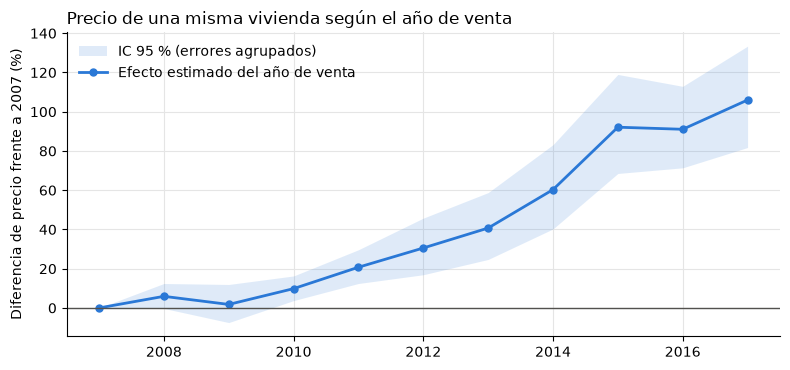

In [27]:
# Indice de precios implicito: efecto de cada año frente a 2007, con IC 95 % agrupado
modelo_anios = ajustar(f"logPrice ~ {resto_tiempo} + C(YrSold) + MonthSold + Bloque")
anios = list(range(2008, 2018))
coef = np.array([modelo_anios.params[f"C(YrSold)[T.{a}]"] for a in anios])
ic = np.array([modelo_anios.conf_int().loc[f"C(YrSold)[T.{a}]"] for a in anios])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between([2007] + anios, (np.exp(np.r_[0, ic[:, 0]]) - 1) * 100, (np.exp(np.r_[0, ic[:, 1]]) - 1) * 100,
                color=AZUL, alpha=0.15, linewidth=0, label="IC 95 % (errores agrupados)")
ax.plot([2007] + anios, (np.exp(np.r_[0, coef]) - 1) * 100, color=AZUL, marker="o", markersize=5, linewidth=2,
        label="Efecto estimado del año de venta")
ax.axhline(0, color=TINTA_2, linewidth=1)
ax.set_ylabel("Diferencia de precio frente a 2007 (%)")
ax.set_title("Precio de una misma vivienda según el año de venta", loc="left")
ax.legend(frameon=False, loc="upper left")
estilo(ax)
plt.tight_layout()
plt.show()

**Interpretación**

* **Año de venta.** Las indicadoras de año son mejores que una tendencia lineal: el AIC baja en 500 puntos,
  y la restricción de linealidad se rechaza con errores agrupados (F = 32,8, p < 0,001). El gráfico muestra
  por qué: los precios casi no cambiaron entre 2007 y 2010, subieron con fuerza entre 2011 y 2015 y se
  estabilizaron entre 2015 y 2016. Las indicadoras comparan el precio de una misma vivienda en distintos años
  sin imponer una forma a la evolución del mercado. Categoría base: 2007.
* **Mes de venta.** Las 11 indicadoras de mes bajan el AIC apenas 4,7 puntos y suben el BIC en 58,6.
  La prueba agrupada rechaza la linealidad (F = 5,3), pero la ganancia en validación es nula
  (VC-10 de 0,1328 frente a 0,1329). Se adopta el mes lineal por parsimonia. Ese término recoge la
  valorización dentro del año, de alrededor de 0,6 % por mes.
* **`Bloque`.** Es la variable de tiempo más importante después del año. Sin ella el AIC sube en
  1.535 puntos y el RMSE VC-10 pasa de 0,133 a 0,160, y su efecto es claramente distinto de cero con errores
  agrupados (F = 110). Codificación: 1 = venta masiva y 0 = venta individual (base).

### 3.4 Interacciones

In [28]:
formula_aditiva = ("logPrice ~ logSize + I(logSize ** 2) + Floor + C(YrSold) + MonthSold + Bloque"
                   " + Antiguedad + I(Antiguedad ** 2) + N_Parkinglot_Basement + N_SchoolNearBy_Total")
aditivo = ajustar(formula_aditiva)
vc10_ad, vcc_ad = rmse_cv(formula_aditiva, kfold), rmse_cv(formula_aditiva, por_conjunto)
print(f"Modelo aditivo: AIC = {aditivo.aic:.1f}, RMSE VC-10 = {vc10_ad:.4f}, RMSE VC-conjunto = {vcc_ad:.4f}")

candidatas_inter = {
    "logSize:Antiguedad": "¿El premio al tamaño cambia con la antigüedad?",
    "logSize:Bloque": "¿El descuento de la venta en bloque depende del tamaño?",
    "Floor:Antiguedad": "¿El premio por piso cambia con la antigüedad?",
    "Antiguedad:YrSold": "¿La depreciación por antigüedad cambia con el año de venta?",
    "logSize:N_Parkinglot_Basement": "¿El premio al tamaño depende de la escala del conjunto?",
    "logSize:N_SchoolNearBy_Total": "¿El premio al tamaño depende del entorno?",
    "Floor:logSize": "¿El premio por piso depende del tamaño?",
    "Floor:N_Parkinglot_Basement": "¿El premio por piso depende de la escala del conjunto?",
}
filas = []
for termino, pregunta in candidatas_inter.items():
    formula = formula_aditiva + " + " + termino
    modelo = ajustar(formula)
    filas.append({"Interaccion": termino, "Pregunta": pregunta, "Coeficiente": modelo.params[termino],
                  "p (agrupado)": modelo.pvalues[termino], "Cambio AIC": modelo.aic - aditivo.aic,
                  "Cambio VC-10": rmse_cv(formula, kfold) - vc10_ad,
                  "Cambio VC-conjunto": rmse_cv(formula, por_conjunto) - vcc_ad})
interacciones = pd.DataFrame(filas).set_index("Interaccion")
interacciones.sort_values("p (agrupado)").round(5)

Modelo aditivo: AIC = -4956.1, RMSE VC-10 = 0.1329, RMSE VC-conjunto = 0.1614


,Pregunta,Coeficiente,p (agrupado),Cambio AIC,Cambio VC-10,Cambio VC-conjunto
Interaccion,,,,,,
logSize:N_Parkinglot_Basement,¿El premio al tamaño depende de la escala del conjunto?,-0.00017,0.00935,-113.78499,-0.00179,-0.00259
Antiguedad:YrSold,¿La depreciación por antigüedad cambia con el año de venta?,0.00136,0.02996,-204.15985,-0.00324,-0.00265
Floor:logSize,¿El premio por piso depende del tamaño?,-0.00419,0.04416,-31.64615,-0.00052,-0.00144
Floor:N_Parkinglot_Basement,¿El premio por piso depende de la escala del conjunto?,-0.00000,0.39771,-4.62450,-0.00006,0.00100
logSize:Antiguedad,¿El premio al tamaño cambia con la antigüedad?,0.00293,0.55517,-18.07913,-0.00027,0.00319
logSize:N_SchoolNearBy_Total,¿El premio al tamaño depende del entorno?,-0.00415,0.62886,-12.90122,-0.00019,0.01587
Floor:Antiguedad,¿El premio por piso cambia con la antigüedad?,0.00002,0.78686,1.71281,0.00001,0.00035
logSize:Bloque,¿El descuento de la venta en bloque depende del tamaño?,-0.02893,0.82339,1.78306,0.00004,0.00762


In [29]:
# Las interacciones que pasan los tres filtros (p < 0,05, menor AIC, menor error en ambas validaciones) se prueban juntas
pasan = interacciones[(interacciones["p (agrupado)"] < 0.05) & (interacciones["Cambio AIC"] < 0)
                      & (interacciones["Cambio VC-10"] < 0) & (interacciones["Cambio VC-conjunto"] < 0)].index.tolist()
print("Interacciones que pasan los filtros individuales:", pasan)
filas = []
for k in range(len(pasan) + 1):
    for S in combinations(pasan, k):
        formula = formula_aditiva + "".join(" + " + s for s in S)
        modelo = ajustar(formula)
        filas.append({"Interacciones": " + ".join(S) or "(ninguna)", "AIC": modelo.aic, "BIC": modelo.bic,
                      "RMSE VC-10": rmse_cv(formula, kfold), "RMSE VC-conjunto": rmse_cv(formula, por_conjunto),
                      "p de cada interaccion (agrupado)": ", ".join(f"{modelo.pvalues[s]:.4f}" for s in S)})
pd.DataFrame(filas).set_index("Interacciones").round(4)

Interacciones que pasan los filtros individuales: ['Antiguedad:YrSold', 'logSize:N_Parkinglot_Basement', 'Floor:logSize']


,AIC,BIC,RMSE VC-10,RMSE VC-conjunto,p de cada interaccion (agrupado)
Interacciones,,,,,
(ninguna),-4956.0718,-4829.5802,0.1329,0.1614,
Antiguedad:YrSold,-5160.2316,-5027.4155,0.1296,0.1587,0.0300
logSize:N_Parkinglot_Basement,-5069.8568,-4937.0406,0.1311,0.1588,0.0094
Floor:logSize,-4987.7179,-4854.9018,0.1324,0.1599,0.0442
Antiguedad:YrSold + logSize:N_Parkinglot_Basement,-5316.1438,-5177.0030,0.1272,0.1530,"0.0127, 0.0050"
Antiguedad:YrSold + Floor:logSize,-5203.3920,-5064.2513,0.1290,0.1564,"0.0224, 0.0314"
logSize:N_Parkinglot_Basement + Floor:logSize,-5071.0492,-4931.9085,0.1311,0.1589,"0.0143, 0.4390"
Antiguedad:YrSold + logSize:N_Parkinglot_Basement + Floor:logSize,-5318.4756,-5173.0102,0.1272,0.1531,"0.0123, 0.0067, 0.3798"


**Interpretación.** De ocho interacciones con sentido económico, tres pasan los filtros individuales:
p < 0,05 con errores agrupados, menor AIC y menor error en las dos validaciones. Al probarlas juntas:

* **Antigüedad × año de venta** (p = 0,013) y **log(tamaño) × parqueaderos en sótano** (p = 0,005) se
  refuerzan entre sí. El modelo con ambas tiene el menor BIC de la tabla (−5.177) y los menores errores
  de validación (VC-10 = 0,1272 y VC-conjunto = 0,1530).
* **Piso × log(tamaño)** deja de ser significativa en presencia de las otras dos (p = 0,38) y no mejora
  ningún criterio. Se descarta.

Lectura de las interacciones incluidas:

* **Antigüedad × año de venta (coeficiente positivo).** La penalización por antigüedad se reduce con el tiempo.
  En los años de mayor valorización, los conjuntos antiguos se valorizaron proporcionalmente más que los nuevos.
* **log(tamaño) × parqueaderos (coeficiente negativo).** La elasticidad precio-tamaño es menor en conjuntos
  con más parqueaderos. Dicho de otra forma, el premio por la escala del conjunto pesa más en las
  viviendas pequeñas.

No se incluyen la interacción del descuento por venta en bloque con el tamaño (p = 0,82), las del premio
por piso con la antigüedad o con la escala, ni las del tamaño con la antigüedad o con el entorno.

### 3.5 Centrado y escala de las variables

In [30]:
def variables_modelo(df):
    df = df.copy()
    df["logSize_c"] = np.log(df["Size_sqf"] / 910)            # 0 = vivienda de 910 pies² (mediana)
    df["Antig_c"] = df["Antiguedad"] - 10                     # 0 = 10 años de antigüedad
    df["YrSold_c"] = df["YrSold"] - 2012                      # 0 = venta en 2012
    df["Parqueo_c"] = (df["N_Parkinglot_Basement"] - 500) / 100  # cientos de parqueaderos, 0 = 500
    return df


train = variables_modelo(train)
test = variables_modelo(test)

formula_sin_centrar = formula_aditiva + " + Antiguedad:YrSold + logSize:N_Parkinglot_Basement"
formula_final = ("logPrice ~ logSize_c + I(logSize_c ** 2) + Floor + C(YrSold) + MonthSold + Bloque"
                 " + Antig_c + I(Antig_c ** 2) + Antig_c:YrSold_c"
                 " + Parqueo_c + logSize_c:Parqueo_c + N_SchoolNearBy_Total")
sin_centrar, centrado = ajustar(formula_sin_centrar), ajustar(formula_final)
print("Mismo ajuste:", np.allclose(sin_centrar.fittedvalues, centrado.fittedvalues),
      f"- R2 {sin_centrar.rsquared:.4f} / {centrado.rsquared:.4f}")

terminos_sin = {"logSize": "logSize", "logSize^2": "I(logSize ** 2)", "Antiguedad": "Antiguedad",
                "Antiguedad^2": "I(Antiguedad ** 2)", "Antiguedad x YrSold": "Antiguedad:YrSold",
                "Parqueaderos": "N_Parkinglot_Basement", "logSize x Parqueaderos": "logSize:N_Parkinglot_Basement"}
terminos_con = {"logSize": "logSize_c", "logSize^2": "I(logSize_c ** 2)", "Antiguedad": "Antig_c",
                "Antiguedad^2": "I(Antig_c ** 2)", "Antiguedad x YrSold": "Antig_c:YrSold_c",
                "Parqueaderos": "Parqueo_c", "logSize x Parqueaderos": "logSize_c:Parqueo_c"}
comunes = {"Floor": "Floor", "Año": "C(YrSold)", "Mes": "MonthSold", "Bloque": "Bloque",
           "Escuelas": "N_SchoolNearBy_Total"}
pd.DataFrame({
    "GVIF^(1/(2gl)) sin centrar": gvif(train, {**terminos_sin, **comunes})["GVIF^(1/(2gl))"],
    "GVIF^(1/(2gl)) centrado": gvif(train, {**terminos_con, **comunes})["GVIF^(1/(2gl))"],
}).round(2)

Mismo ajuste: True - R2 0.9475 / 0.9475


,GVIF^(1/(2gl)) sin centrar,GVIF^(1/(2gl)) centrado
logSize,19.14,1.36
logSize^2,19.85,1.35
Antiguedad,805.58,1.99
Antiguedad^2,4.19,1.72
Antiguedad x YrSold,807.72,1.25
Parqueaderos,22.13,1.57
logSize x Parqueaderos,22.26,1.30
Floor,1.10,1.10
Año,1.08,1.04
Mes,1.09,1.09


**Interpretación.** Con interacciones y términos cuadráticos, el coeficiente de un efecto principal mide el
efecto cuando las demás variables valen cero. Sin centrar, ese cero es una venta en el año 0 o una vivienda
de 1 pie², algo que no tiene sentido. Por eso se centran las variables que participan en interacciones
o cuadrados:

| Variable | Definición | Valor de referencia (= 0) |
|---|---|---|
| `logSize_c` | log(Size / 910) | 910 pies², la mediana |
| `Antig_c` | Antigüedad − 10 | 10 años (la media es 9,7) |
| `YrSold_c` | YrSold − 2012 | Mitad del período |
| `Parqueo_c` | (Parqueaderos en sótano − 500) / 100 | 500 parqueaderos (la mediana es 536), en cientos |

El centrado no cambia el ajuste: los valores ajustados son idénticos y $R^2$ = 0,9475 en ambas versiones.
Sí elimina la multicolinealidad entre cada variable y sus términos derivados. El GVIF$^{1/(2gl)}$ de la
antigüedad baja de 806 a 2,0 y el del tamaño de 19 a 1,4. Con las variables centradas todos los valores
quedan en 2 o menos, así que la multicolinealidad del modelo final es baja.

### 3.6 Estructura del término de error

In [31]:
mco = ajustar(formula_final, robusto=False)
bp = het_breuschpagan(mco.resid, mco.model.exog)
print(f"Breusch-Pagan: estadistico = {bp[0]:.1f}, p = {bp[1]:.2e}")

# Correlacion de los residuos dentro de un conjunto: parte de su varianza que es comun al conjunto
residuos = pd.DataFrame({"r": mco.resid, "complejo": train["complejo"]})
icc = smf.ols("r ~ C(complejo)", residuos).fit().rsquared
print(f"Proporcion de la varianza residual explicada por el conjunto: {icc:.3f}")
desv = residuos.groupby("complejo")["r"].agg(["std", "size"])
print(f"Desviacion estandar residual por conjunto (con 15 o mas ventas): de {desv.loc[desv['size'] >= 15, 'std'].min():.3f}"
      f" a {desv.loc[desv['size'] >= 15, 'std'].max():.3f}")

# Errores estandar segun el supuesto sobre el error
hc3 = smf.ols(formula_final, train).fit(cov_type="HC3")
agrupado = ajustar(formula_final)
# Minimos cuadrados ponderados: peso inverso a la varianza residual de cada conjunto
varianza_conjunto = residuos.groupby("complejo")["r"].var().clip(lower=residuos["r"].var() / 10)
pesos = 1 / train["complejo"].map(varianza_conjunto)
mcp = smf.wls(formula_final, train, weights=pesos).fit(cov_type="cluster", cov_kwds={"groups": train["complejo"]},
                                                        use_t=True)
seleccion_coef = ["logSize_c", "I(logSize_c ** 2)", "Floor", "MonthSold", "Bloque", "Antig_c", "I(Antig_c ** 2)",
                  "Antig_c:YrSold_c", "Parqueo_c", "logSize_c:Parqueo_c", "N_SchoolNearBy_Total"]
comparacion_ee = pd.DataFrame({
    "Coef. MCO": mco.params, "EE MCO clasico": mco.bse, "EE HC3": hc3.bse, "EE agrupado": agrupado.bse,
    "Razon agrupado / clasico": agrupado.bse / mco.bse, "Coef. MCP": mcp.params, "EE MCP agrupado": mcp.bse,
}).loc[seleccion_coef]
comparacion_ee.round(4)

Breusch-Pagan: estadistico = 282.8, p = 1.01e-47
Proporcion de la varianza residual explicada por el conjunto: 0.292
Desviacion estandar residual por conjunto (con 15 o mas ventas): de 0.055 a 0.178


,Coef. MCO,EE MCO clasico,EE HC3,EE agrupado,Razon agrupado / clasico,Coef. MCP,EE MCP agrupado
logSize_c,0.8087,0.0064,0.0085,0.0511,7.9231,0.8010,0.0418
I(logSize_c ** 2),-0.0900,0.0071,0.0106,0.0448,6.3184,-0.1319,0.0462
Floor,0.0037,0.0003,0.0003,0.0006,2.1097,0.0034,0.0006
MonthSold,0.0059,0.0006,0.0007,0.0012,1.9453,0.0069,0.0009
Bloque,-0.4793,0.0103,0.0097,0.0353,3.4168,-0.4621,0.0301
Antig_c,-0.0211,0.0005,0.0005,0.0032,7.0526,-0.0217,0.0027
I(Antig_c ** 2),0.0003,0.0000,0.0000,0.0002,4.8387,0.0003,0.0002
Antig_c:YrSold_c,0.0015,0.0001,0.0001,0.0005,5.9419,0.0014,0.0005
Parqueo_c,0.0193,0.0008,0.0008,0.0042,5.4921,0.0153,0.0040
logSize_c:Parqueo_c,-0.0197,0.0016,0.0018,0.0064,4.1081,-0.0133,0.0074


**Interpretación.** El término de error tiene dos características que afectan la inferencia:

1. **Heterocedasticidad.** La prueba de Breusch-Pagan la detecta (estadístico = 282,8). La desviación estándar
   residual varía entre conjuntos de 0,055 a 0,178.
2. **Correlación dentro del conjunto.** El 29,2 % de la varianza residual es común a las ventas de un mismo
   conjunto, así que los errores de dos ventas del mismo conjunto no son independientes.

Los errores estándar clásicos de MCO ignoran ambas cosas. Los errores agrupados por conjunto son entre
1,9 y 7,9 veces mayores que los clásicos, sobre todo en el tamaño y en las variables de conjunto.
Los errores HC3 corrigen solo la heterocedasticidad y cambian poco, lo que confirma que el problema principal
es la correlación dentro del conjunto.

Se evaluó mínimos cuadrados ponderados (MCP) con pesos inversos a la varianza residual de cada conjunto.
Los coeficientes son similares a los de MCO y los errores agrupados bajan poco. Los pesos se estiman con
conjuntos muy pequeños (el conjunto 1 tiene 3 ventas), y la ganancia en eficiencia no compensa depender de
una función de varianza estimada.

**Decisión: MCO con errores estándar agrupados por conjunto.** Se usa el estimador CR1 con 26 conglomerados
y la distribución t con 25 grados de libertad. Es válido ante heterocedasticidad y ante correlación dentro del
conjunto, y es la base para los intervalos de confianza y las pruebas de hipótesis de las etapas siguientes.
La verificación formal de los supuestos (normalidad, observaciones influyentes) corresponde a la etapa
siguiente del informe.

### 3.7 Modelo final

**Especificación del modelo final** (22 parámetros). Para la venta $i$, ubicada en el conjunto $c(i)$:

$$
\begin{aligned}
\log(\text{Precio}_i) = {} & \beta_0 + \beta_1\,\tilde s_i + \beta_2\,\tilde s_i^{2} + \beta_3\,\text{Piso}_i
+ \sum_{a=2008}^{2017}\gamma_a\,\mathbb{1}[\text{Año}_i = a] + \beta_4\,\text{Mes}_i + \beta_5\,\text{Bloque}_i \\
& + \beta_6\,\tilde A_i + \beta_7\,\tilde A_i^{2} + \beta_8\,\tilde A_i\,\tilde T_i
+ \beta_9\,\tilde P_{c(i)} + \beta_{10}\,\tilde s_i\,\tilde P_{c(i)} + \beta_{11}\,\text{Escuelas}_{c(i)} + \varepsilon_i
\end{aligned}
$$

Donde:

* $\tilde s = \log(\text{Size}/910)$.
* $\tilde A = \text{Antigüedad} - 10$.
* $\tilde T = \text{Año} - 2012$.
* $\tilde P = (\text{Parqueaderos en sótano} - 500)/100$.
* $\varepsilon_i$ tiene media cero y puede tener varianza distinta y estar correlacionado con los errores
  de otras ventas del mismo conjunto. Por eso la inferencia usa errores estándar agrupados por conjunto.

In [32]:
modelo_final = ajustar(formula_final)
tabla = pd.DataFrame({"Coeficiente": modelo_final.params, "EE agrupado": modelo_final.bse,
                      "t": modelo_final.tvalues, "p": modelo_final.pvalues})
print(f"n = {int(modelo_final.nobs)}, parametros = {int(modelo_final.df_model) + 1}, "
      f"R2 = {modelo_final.rsquared:.4f}, R2 ajustado = {modelo_final.rsquared_adj:.4f}, "
      f"conjuntos (conglomerados) = {train['complejo'].nunique()}")
tabla.round(5)

n = 4124, parametros = 22, R2 = 0.9475, R2 ajustado = 0.9472, conjuntos (conglomerados) = 26


,Coeficiente,EE agrupado,t,p
Intercept,11.91598,0.09318,127.88244,0.00000
C(YrSold)[T.2008],0.05583,0.02767,2.01819,0.05442
C(YrSold)[T.2009],0.01061,0.04411,0.24052,0.81189
C(YrSold)[T.2010],0.08510,0.02940,2.89442,0.00777
C(YrSold)[T.2011],0.18105,0.03176,5.70104,0.00001
C(YrSold)[T.2012],0.26038,0.04600,5.66023,0.00001
C(YrSold)[T.2013],0.34052,0.04896,6.95506,0.00000
C(YrSold)[T.2014],0.46564,0.05457,8.53230,0.00000
C(YrSold)[T.2015],0.64357,0.05511,11.67759,0.00000
C(YrSold)[T.2016],0.64582,0.04796,13.46568,0.00000


In [33]:
# Verificacion de la escala de la respuesta con la estructura final
lam_final, ic_final = perfil_boxcox(formula_final.split("~")[1])[:2]
print(f"Box-Cox con la estructura final: lambda = {lam_final:.3f} (IC 95 %: {ic_final[0]:.3f} a {ic_final[1]:.3f})")
comparar_respuestas(formula_final.split("~")[1]).round(3)

Box-Cox con la estructura final: lambda = 0.190 (IC 95 %: 0.175 a 0.200)


,Breusch-Pagan,Asimetria residuos,Curtosis exceso,"Corr(|residuo|, ajustado)",RMSE VC-10 (USD)
Respuesta,,,,,
Nivel (lambda = 1),805.397,0.280,1.679,0.153,31427.714
Box-Cox (lambda = 0.19),315.296,-0.374,2.742,0.031,28433.551
Logaritmo (lambda = 0),282.766,-0.498,3.488,-0.053,29648.004


In [34]:
# Comparacion con modelos de referencia
formula_saturado_bic = "logPrice ~ " + base_vivienda + "".join(" + " + grupos_conjunto[g] for g in mejor_bic)
formula_efectos_fijos = ("logPrice ~ C(complejo) + logSize_c + I(logSize_c ** 2) + Floor + C(YrSold) + MonthSold"
                         " + Bloque + I(Antig_c ** 2) + Antig_c:YrSold_c + logSize_c:Parqueo_c")
referencias = {
    "Solo vivienda y tiempo": "logPrice ~ " + base_vivienda,
    "Variables seleccionadas, forma aditiva": formula_aditiva,
    "Modelo final": formula_final,
    f"Mejor BIC ingenuo ({len(mejor_bic)} variables de conjunto)": formula_saturado_bic,
    "Indicador por conjunto (efectos fijos)": formula_efectos_fijos,
}
filas = []
for nombre, formula in referencias.items():
    modelo = ajustar(formula, robusto=False)
    filas.append({"Modelo": nombre, "Parametros": int(np.linalg.matrix_rank(modelo.model.exog)),
                  "R2 ajustado": modelo.rsquared_adj, "AIC": modelo.aic, "BIC": modelo.bic,
                  "RMSE VC-10": rmse_cv(formula, kfold),
                  "RMSE VC-conjunto": "no aplica" if "C(complejo)" in formula
                  else formato_error(rmse_cv(formula, por_conjunto))})
comparacion_modelos = pd.DataFrame(filas).set_index("Modelo")
comparacion_modelos.round(4)

,Parametros,R2 ajustado,AIC,BIC,RMSE VC-10,RMSE VC-conjunto
Modelo,,,,,,
Solo vivienda y tiempo,16,0.8089,-16.0622,85.1311,0.2419,0.2906
"Variables seleccionadas, forma aditiva",20,0.9424,-4956.0718,-4829.5802,0.1329,0.1614
Modelo final,22,0.9472,-5316.1438,-5177.0030,0.1272,0.1530
Mejor BIC ingenuo (12 variables de conjunto),38,0.9604,-6486.9461,-6246.6121,0.1106,2.2e+08 (explota)
Indicador por conjunto (efectos fijos),43,0.9665,-7176.1139,-6904.1570,0.1025,no aplica


**Interpretación.** El modelo final tiene 22 parámetros y explica el 94,7 % de la variación del log-precio
($R^2$ ajustado = 0,9472). Todos los coeficientes son distintos de cero al 5 % con errores agrupados, salvo tres:

* El cuadrado del log-tamaño (p = 0,055). Se conserva por su aporte a AIC, BIC y VC-10 (sección 3.2);
  su contraste formal corresponde a la etapa de pruebas de hipótesis.
* Las indicadoras de 2008 y 2009, que forman parte de un factor conjuntamente significativo.

La escala de la respuesta se verificó con la estructura final: $\hat\lambda$ = 0,19, el log tiene menor
heterocedasticidad que la transformación con $\hat\lambda$, y la escala original es claramente peor en todos
los diagnósticos.

**Frente a los modelos de referencia**

* **Sin variables de conjunto**, el modelo final reduce el RMSE VC-10 de 0,242 a 0,127 y el VC-conjunto
  de 0,291 a 0,153.
* **Frente a la forma aditiva**, la forma funcional y las interacciones reducen los dos errores de validación
  (VC-10 de 0,133 a 0,127; VC-conjunto de 0,161 a 0,153).
* **El mejor modelo por BIC ingenuo** (12 variables de conjunto) y el **indicador por conjunto** predicen
  mejor ventas nuevas de los mismos conjuntos (VC-10 de 0,111 y 0,103). Pero el primero no generaliza a
  conjuntos nuevos (su VC-conjunto explota) y el segundo no estima el efecto de ninguna característica del
  conjunto. Ganan precisión a costa de no poder responder qué explica el precio, así que su uso se reserva
  para la predicción (sección 4).

**Pendientes para las siguientes etapas del informe**

* Verificar la normalidad de los residuos (curtosis en exceso de 3,5 en log) y las observaciones influyentes.
  Por ejemplo, el conjunto 1 tiene 3 ventas con año de construcción 1980, pero sus demás características son
  idénticas a las del conjunto 22, construido en 2014; puede tratarse de un error de registro.
* Construir los intervalos de confianza y las pruebas con los errores agrupados del objeto `modelo_final`.
* Interpretar los coeficientes como cambios porcentuales, $100\,(e^{\beta}-1)$. En las variables con término
  cuadrático o interacción, el efecto marginal depende del punto de referencia fijado por el centrado (3.5).

## 4. Predicciones para la competencia

La competencia evalúa el error cuadrático medio del precio en dólares. El modelo predice el logaritmo
del precio, así que la predicción en dólares es $\exp(\widehat{\log P})$, que estima la mediana
condicional. La media condicional se puede aproximar con el factor de *smearing* de Duan,
$\exp(\widehat{\log P})\cdot \frac{1}{n}\sum_i e^{\hat\varepsilon_i}$.

Con validación cruzada de 10 pliegues en dólares se comparan:

* las dos retransformaciones del modelo final;
* el modelo final con la respuesta de Box-Cox ($\hat\lambda$ de la sección 3.7);
* una variante predictiva que reemplaza las variables de conjunto por un indicador por conjunto
  (efectos fijos), en log y con Box-Cox.

La variante con efectos fijos no sirve para interpretar las características del conjunto, pero sí para
predecir, porque los 26 conjuntos de prueba están en entrenamiento.

In [35]:
def transformar(precio, lam):
    return np.log(precio) if lam == 0 else (precio ** lam - 1) / lam


def invertir(z, lam):
    return np.exp(z) if lam == 0 else np.clip(lam * z + 1, 1e-9, None) ** (1 / lam)


def predecir_dolares(rhs, lam, ajuste, nuevos, smearing=False):
    datos = ajuste.assign(respuesta=transformar(ajuste["SalePrice"], lam))
    modelo = smf.ols("respuesta ~ " + rhs, datos).fit()
    pred = invertir(modelo.predict(nuevos), lam)
    return pred * np.exp(modelo.resid).mean() if smearing else pred


def rmse_dolares(rhs, lam, smearing=False):
    errores = []
    for ajuste, valida in kfold.split(train):
        pred = predecir_dolares(rhs, lam, train.iloc[ajuste], train.iloc[valida], smearing)
        errores.append((train["SalePrice"].iloc[valida] - pred) ** 2)
    return float(np.sqrt(pd.concat(errores).mean()))


rhs_final = formula_final.split("~")[1]
rhs_efectos = formula_efectos_fijos.split("~")[1]
opciones = {
    "Modelo final, log, exp(prediccion)": (rhs_final, 0, False),
    "Modelo final, log, con smearing": (rhs_final, 0, True),
    f"Modelo final, Box-Cox (lambda = {lam_final:.2f})": (rhs_final, lam_final, False),
    "Indicador por conjunto, log, exp(prediccion)": (rhs_efectos, 0, False),
    f"Indicador por conjunto, Box-Cox (lambda = {lam_final:.2f})": (rhs_efectos, lam_final, False),
}
rmse_usd = pd.Series({nombre: rmse_dolares(*args) for nombre, args in opciones.items()}, name="RMSE VC-10 (USD)")
print(f"Precio medio en train: USD {train['SalePrice'].mean():,.0f}")
rmse_usd.round(0).to_frame()

Precio medio en train: USD 221,688


,RMSE VC-10 (USD)
"Modelo final, log, exp(prediccion)",29648.0
"Modelo final, log, con smearing",29708.0
"Modelo final, Box-Cox (lambda = 0.19)",28434.0
"Indicador por conjunto, log, exp(prediccion)",25732.0
"Indicador por conjunto, Box-Cox (lambda = 0.19)",24632.0


In [36]:
def guardar_predicciones(nombre_opcion, archivo):
    pred = predecir_dolares(*opciones[nombre_opcion][:2], train, test, opciones[nombre_opcion][2])
    salida = pd.DataFrame({"id": test["id"], "SalePrice": pred.to_numpy()})
    assert len(salida) == len(df_test) and salida["SalePrice"].notna().all() and (salida["SalePrice"] > 0).all()
    salida.to_csv(archivo, index=False)
    print(f"{archivo}: {nombre_opcion} - {len(salida)} filas, precio predicho medio USD {salida['SalePrice'].mean():,.0f}")
    return salida


# Archivo 1: el modelo final del informe. Archivo 2: la opcion con menor error de validacion en dolares
pred_final = guardar_predicciones("Modelo final, log, exp(prediccion)", "submission_modelo_final.csv")
pred_mejor = guardar_predicciones(rmse_usd.idxmin(), "submission_mejor_prediccion.csv")
print("Correlacion entre ambas predicciones:", round(np.corrcoef(pred_final["SalePrice"], pred_mejor["SalePrice"])[0, 1], 4))
pred_mejor.head()

submission_modelo_final.csv: Modelo final, log, exp(prediccion) - 1767 filas, precio predicho medio USD 226,572
submission_mejor_prediccion.csv: Indicador por conjunto, Box-Cox (lambda = 0.19) - 1767 filas, precio predicho medio USD 226,066
Correlacion entre ambas predicciones: 0.9845


,id,SalePrice
0,100001,94983.537991
1,100002,266865.142554
2,100003,319410.179550
3,100004,105511.934640
4,100005,393058.912006


**Interpretación.** Errores de validación en dólares:

* **Smearing.** No mejora la retransformación del log (29.708 frente a 29.648 USD), así que se usa
  $\exp(\widehat{\log P})$ directamente.
* **Box-Cox.** Con el $\hat\lambda$ de máxima verosimilitud baja el error tanto del modelo final (28.434 USD)
  como de la variante con indicador por conjunto (24.632 USD). Como la métrica se mide en dólares, una escala
  menos comprimida que el log da más peso a las viviendas caras.
* **Indicador por conjunto con Box-Cox.** Es la opción más precisa, con un error cercano al 11 % del precio medio.

Se generan dos archivos con el formato `id,SalePrice` y 1.767 filas:

* `submission_modelo_final.csv`: predicciones del modelo final del informe (log con retransformación exponencial).
  Es coherente con el modelo que se interpreta.
* `submission_mejor_prediccion.csv`: la opción con menor error de validación (indicador por conjunto con
  Box-Cox). Es la recomendada para la tabla de posiciones de Kaggle.

## 5. Estimación de parámetros y verificación de supuestos

### 5.1 Estimación de los parámetros

Los coeficientes se estiman por mínimos cuadrados ordinarios. Se comparan los errores estándar clásicos con los agrupados por conjunto, que se conservan para la inferencia. La tabla separa los coeficientes del cálculo de su incertidumbre.

In [ ]:
from scipy import stats
tabla_parametros = pd.DataFrame({
    'Coeficiente': modelo_final.params,
    'EE clásico': mco.bse,
    'EE agrupado': modelo_final.bse
})
print('Ventas:', int(modelo_final.nobs))
print('Parámetros:', len(modelo_final.params))
print('Rango de la matriz:', np.linalg.matrix_rank(mco.model.exog))
print('Varianza residual clásica:', round(mco.mse_resid, 6))
display(tabla_parametros.round(5))


Ventas: 4124
Parámetros: 22
Rango de la matriz: 22
Varianza residual clásica: 0.016046


,Coeficiente,EE clásico,EE agrupado
Intercept,11.91598,0.01827,0.09318
C(YrSold)[T.2008],0.05583,0.01631,0.02767
C(YrSold)[T.2009],0.01061,0.01583,0.04411
C(YrSold)[T.2010],0.08510,0.01565,0.02940
C(YrSold)[T.2011],0.18105,0.01587,0.03176
C(YrSold)[T.2012],0.26038,0.01607,0.04600
C(YrSold)[T.2013],0.34052,0.01570,0.04896
C(YrSold)[T.2014],0.46564,0.01557,0.05457
C(YrSold)[T.2015],0.64357,0.01600,0.05511
C(YrSold)[T.2016],0.64582,0.01577,0.04796


### 5.2 Verificación de los supuestos

Se examinan los residuos del mismo modelo estimado. Las pruebas se acompañan con gráficos porque la agrupación por conjunto limita la lectura de los valores p clásicos.

#### 5.2.1 Forma funcional y varianza

En los gráficos se buscan curvaturas y cambios de dispersión. Breusch–Pagan contrasta varianza constante; su valor p se reporta como referencia nominal bajo los supuestos clásicos.

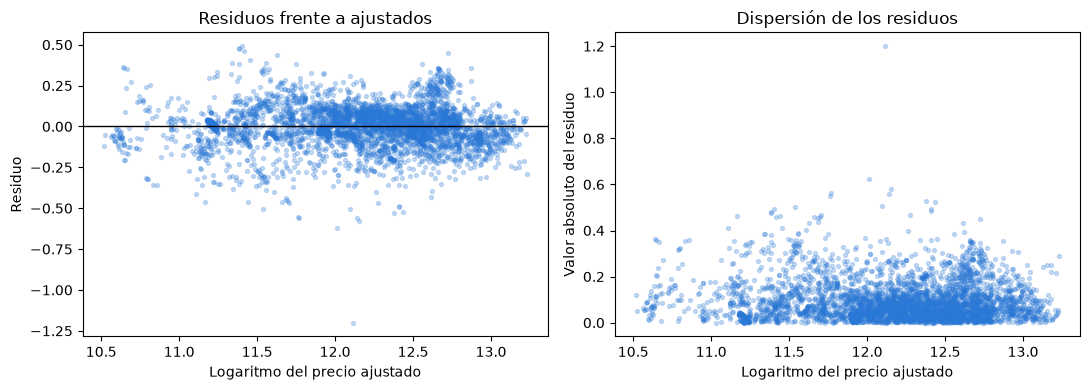

Breusch–Pagan: LM = 282.77, p nominal = 1.01e-47


In [39]:
residuos = mco.resid
ajustados = mco.fittedvalues
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(ajustados, residuos, s=8, alpha=0.25, color=AZUL)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(xlabel='Logaritmo del precio ajustado', ylabel='Residuo', title='Residuos frente a ajustados')
axes[1].scatter(ajustados, np.abs(residuos), s=8, alpha=0.25, color=AZUL)
axes[1].set(xlabel='Logaritmo del precio ajustado', ylabel='Valor absoluto del residuo', title='Dispersión de los residuos')
plt.tight_layout()
plt.show()

print(f'Breusch–Pagan: LM = {bp[0]:.2f}, p nominal = {bp[1]:.3g}')


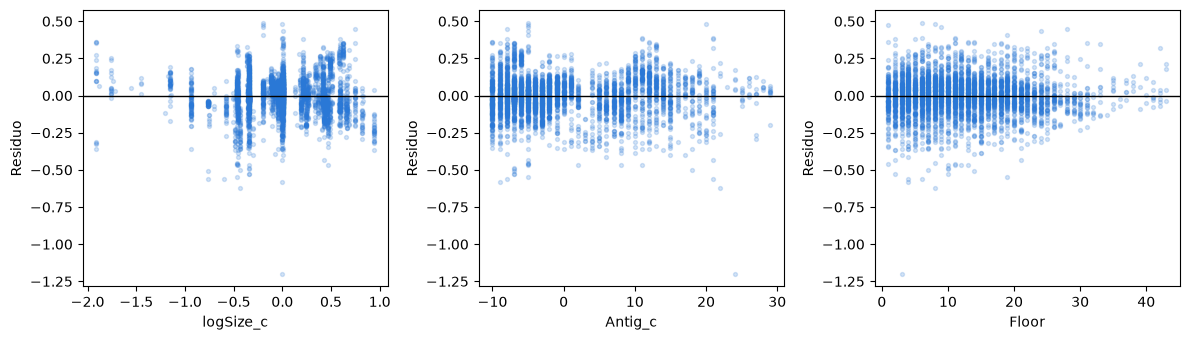

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, variable in zip(axes, ['logSize_c', 'Antig_c', 'Floor']):
    ax.scatter(train[variable], residuos, s=8, alpha=0.2, color=AZUL)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel=variable, ylabel='Residuo')
plt.tight_layout()
plt.show()


#### 5.2.2 Normalidad

El histograma y el Q–Q muestran asimetría y colas. Jarque–Bera es complementario: con muchas ventas y dependencia dentro de conjuntos, no debe usarse como único criterio. La normalidad no es necesaria para calcular los coeficientes MCO.

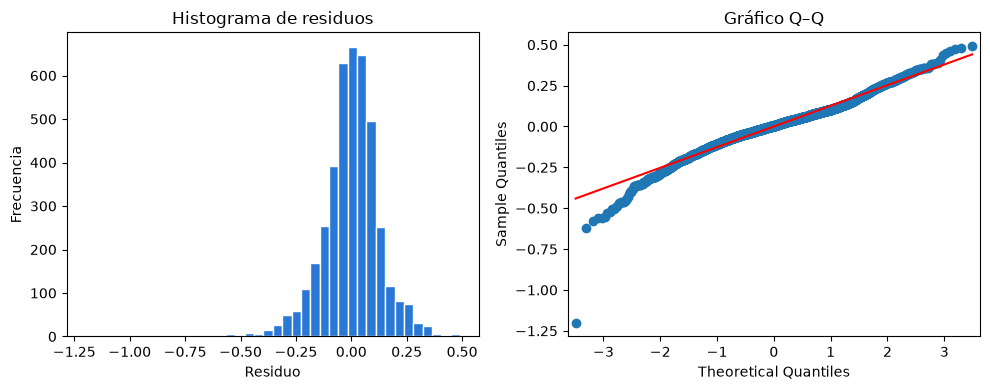

Jarque–Bera = 2253.63; p nominal = 0
Asimetría = -0.50
Exceso de curtosis = 3.48


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(residuos, bins=40, color=AZUL, edgecolor='white')
axes[0].set(xlabel='Residuo', ylabel='Frecuencia', title='Histograma de residuos')
sm.qqplot(residuos, line='s', ax=axes[1])
axes[1].set_title('Gráfico Q–Q')
plt.tight_layout()
plt.show()

jb = stats.jarque_bera(residuos)
print(f'Jarque–Bera = {jb.statistic:.2f}; p nominal = {jb.pvalue:.3g}')
print(f'Asimetría = {stats.skew(residuos):.2f}')
print(f'Exceso de curtosis = {stats.kurtosis(residuos):.2f}')


#### 5.2.3 Dependencia entre las observaciones

Las ventas comparten características dentro de cada conjunto. Se examinan sus residuos medios y el comportamiento temporal. El R² por conjunto es descriptivo; no es una correlación intraclase ni una prueba formal de independencia. Por eso se conserva la covarianza agrupada de Silvia. Con 26 conjuntos, la inferencia sigue siendo aproximada.

,size,mean,std
complejo,,,
0,51,0.0612,0.1354
1,3,-0.6119,0.5228
2,45,-0.2556,0.1161
3,212,0.0895,0.1167
4,54,-0.0793,0.0733
5,116,-0.0235,0.1291
6,206,-0.0507,0.1210
7,467,0.0272,0.1205
8,68,-0.2056,0.1137


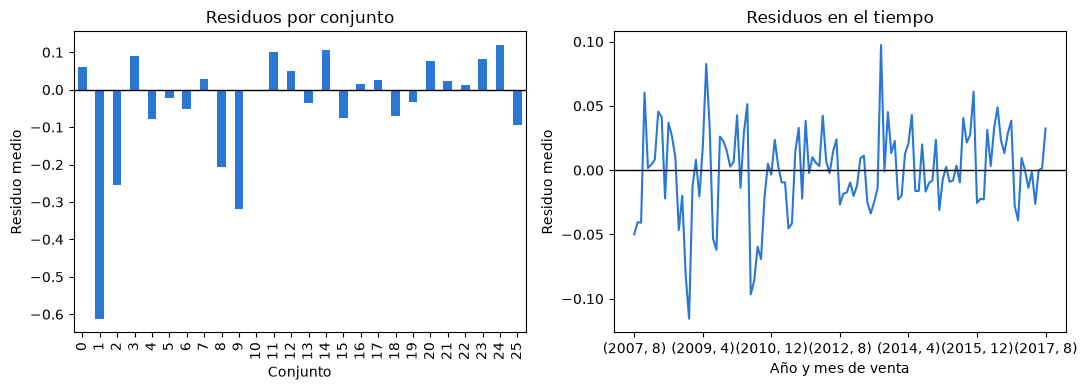

Variación residual asociada descriptivamente al conjunto: 29.2 %


In [42]:
revision = train[['id', 'complejo', 'YrSold', 'MonthSold']].copy()
revision['residuo'] = residuos.to_numpy()
por_conjunto = revision.groupby('complejo')['residuo'].agg(['size', 'mean', 'std'])
display(por_conjunto.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
por_conjunto['mean'].plot.bar(ax=axes[0], color=AZUL)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(xlabel='Conjunto', ylabel='Residuo medio', title='Residuos por conjunto')
por_mes = revision.groupby(['YrSold', 'MonthSold'])['residuo'].mean()
por_mes.plot(ax=axes[1], color=AZUL)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(xlabel='Año y mes de venta', ylabel='Residuo medio', title='Residuos en el tiempo')
plt.tight_layout()
plt.show()

r2_conjunto = icc
print(f'Variación residual asociada descriptivamente al conjunto: {100*r2_conjunto:.1f} %')


#### 5.2.4 Observaciones que requieren revisión

Los residuos estandarizados, el apalancamiento y Cook señalan ventas a inspeccionar. Los umbrales no justifican eliminar registros automáticamente. Se conservan las ventas en bloque y los datos originales.

In [43]:
influencia = mco.get_influence()
revision['residuo_estandarizado'] = influencia.resid_studentized_internal
revision['apalancamiento'] = influencia.hat_matrix_diag
revision['Cook'] = influencia.cooks_distance[0]
n = int(mco.nobs)
p = len(mco.params)
revision['revisar'] = ((revision['residuo_estandarizado'].abs() > 3)
                       | (revision['apalancamiento'] > 2*p/n)
                       | (revision['Cook'] > 4/n))
print('Ventas señaladas para revisión:', int(revision['revisar'].sum()))
display(revision.loc[revision['revisar']].sort_values('Cook', ascending=False).head(15).round(4))


Ventas señaladas para revisión: 400


,id,complejo,YrSold,MonthSold,residuo,residuo_estandarizado,apalancamiento,Cook,revisar
2642,3798,1,2014,10,-1.2000,-9.5361,0.0131,0.0551,True
3978,5676,2,2017,7,-0.6229,-4.9419,0.0098,0.0110,True
224,324,0,2008,6,0.4790,3.8096,0.0149,0.0100,True
2510,3603,23,2014,7,0.3624,2.8982,0.0253,0.0099,True
3155,4522,23,2015,12,-0.3565,-2.8516,0.0258,0.0098,True
2509,3602,23,2014,7,0.3587,2.8685,0.0253,0.0097,True
2558,3665,23,2014,8,0.3511,2.8076,0.0255,0.0094,True
3649,5200,2,2016,11,-0.5609,-4.4494,0.0098,0.0089,True
3153,4520,19,2015,12,-0.5589,-4.4321,0.0089,0.0081,True
3044,4349,23,2015,7,-0.3231,-2.5829,0.0247,0.0077,True


#### 5.2.5 Síntesis

Los errores agrupados ajustan la incertidumbre, pero no corrigen por sí solos una media mal especificada. La media de los residuos cercana a cero no demuestra exogeneidad. Los VIF y el centrado ya fueron tratados en el apartado de estructura del modelo de Silvia.

In [44]:
sintesis = pd.DataFrame({
    'Aspecto': ['Identificación', 'Varianza constante', 'Normalidad marginal', 'Agrupación', 'Influencia'],
    'Resultado': [
        f"Rango {np.linalg.matrix_rank(mco.model.exog)} de {len(mco.params)} columnas",
        f'Breusch–Pagan: LM={bp[0]:.2f}; p nominal={bp[1]:.3g}',
        f'Jarque–Bera={jb.statistic:.2f}; p nominal={jb.pvalue:.3g}',
        f"{train['complejo'].nunique()} conjuntos; R² descriptivo={r2_conjunto:.3f}",
        f"{int(revision['revisar'].sum())} ventas señaladas"
    ]
})
display(sintesis)

tabla_parametros.to_csv('Parametros_Andres.csv', encoding='utf-8-sig')
sintesis.to_csv('Diagnostico_Andres.csv', index=False, encoding='utf-8-sig')
revision.loc[revision['revisar']].to_csv('Ventas_a_revisar.csv', index=False)


,Aspecto,Resultado
0,Identificación,Rango 22 de 22 columnas
1,Varianza constante,Breusch–Pagan: LM=282.77; p nominal=1.01e-47
2,Normalidad marginal,Jarque–Bera=2253.63; p nominal=0
3,Agrupación,26 conjuntos; R² descriptivo=0.292
4,Influencia,400 ventas señaladas


### 5.3 Revisión de sensibilidad

Se inspecciona la venta 3798 y se comparan dos exclusiones concretas. El modelo principal no se modifica.


In [45]:
# Revisión del caso con mayor residuo y sensibilidad del ajuste
caso = train.loc[train['id'] == 3798]
columnas = ['id','SalePrice','YearBuilt','YrSold','MonthSold','Size_sqf','Floor','SubwayStation','N_Parkinglot_Ground','N_Parkinglot_Basement','complejo']
display(caso[columnas])
referencia = caso.iloc[0]
vecinos = train.loc[(train['SubwayStation'] == referencia['SubwayStation']) & (train['N_Parkinglot_Ground'] == referencia['N_Parkinglot_Ground']) & (train['N_Parkinglot_Basement'] == referencia['N_Parkinglot_Basement'])]
display(vecinos.groupby(['YearBuilt','complejo']).agg(Ventas=('id','size'), Precio_medio=('SalePrice','mean')))
sin_caso = smf.ols(formula_final, train.loc[train['id'] != 3798]).fit()
sin_conjunto = smf.ols(formula_final, train.loc[train['complejo'] != referencia['complejo']]).fit()
sensibilidad = pd.DataFrame({'Modelo completo': mco.params, 'Sin venta 3798': sin_caso.params, 'Sin conjunto del caso': sin_conjunto.params, 'EE agrupado completo': modelo_final.bse})
sensibilidad['Cambio sin venta / EE'] = (sensibilidad['Sin venta 3798'] - sensibilidad['Modelo completo']) / sensibilidad['EE agrupado completo']
sensibilidad['Cambio sin conjunto / EE'] = (sensibilidad['Sin conjunto del caso'] - sensibilidad['Modelo completo']) / sensibilidad['EE agrupado completo']
display(sensibilidad.round(5))
print('Rangos de las matrices de sensibilidad:', np.linalg.matrix_rank(sin_caso.model.exog), np.linalg.matrix_rank(sin_conjunto.model.exog))
print('Máximo Cook:', round(revision['Cook'].max(), 5))
sensibilidad.to_csv('Sensibilidad_Andres.csv', encoding='utf-8-sig')


,id,SalePrice,YearBuilt,YrSold,MonthSold,Size_sqf,Floor,SubwayStation,N_Parkinglot_Ground,N_Parkinglot_Basement,complejo
2642,3798,54867,1980,2014,10,910,3,Myung-duk,90,1174,1


,,Ventas,Precio_medio
YearBuilt,complejo,,
1980,1,3,74926.000000
2014,22,140,317726.421429


,Modelo completo,Sin venta 3798,Sin conjunto del caso,EE agrupado completo,Cambio sin venta / EE,Cambio sin conjunto / EE
Intercept,11.91598,11.91370,11.91353,0.09318,-0.02441,-0.02622
C(YrSold)[T.2008],0.05583,0.05626,0.05626,0.02767,0.01555,0.01544
C(YrSold)[T.2009],0.01061,0.01108,0.01190,0.04411,0.01076,0.02927
C(YrSold)[T.2010],0.08510,0.08542,0.08546,0.02940,0.01069,0.01210
C(YrSold)[T.2011],0.18105,0.18150,0.18254,0.03176,0.01422,0.04679
C(YrSold)[T.2012],0.26038,0.26068,0.26053,0.04600,0.00646,0.00325
C(YrSold)[T.2013],0.34052,0.34024,0.33976,0.04896,-0.00562,-0.01552
C(YrSold)[T.2014],0.46564,0.46814,0.46779,0.05457,0.04569,0.03928
C(YrSold)[T.2015],0.64357,0.64337,0.64288,0.05511,-0.00374,-0.01254
C(YrSold)[T.2016],0.64582,0.64501,0.64423,0.04796,-0.01682,-0.03319


Rangos de las matrices de sensibilidad: 22 22
Máximo Cook: 0.05507


### 5.4 Síntesis de resultados

#### 5.4.1 Estimación de parámetros

Se mantuvo la estructura del modelo seleccionada previamente y se estimaron sus parámetros por mínimos cuadrados ordinarios. La respuesta es el logaritmo natural del precio de venta. La especificación incluye el tamaño, el piso, el momento de la venta, las ventas en bloque, la antigüedad, los parqueaderos en sótano y las escuelas cercanas, junto con los términos cuadrados e interacciones definidos en el apartado de estructura.

El ajuste utiliza 4.124 ventas y 22 parámetros, incluido el intercepto. La matriz de diseño tiene rango 22, por lo que los coeficientes están identificados. La varianza residual clásica estimada es 0,016046 en escala logarítmica. Se conservaron los centrados: logaritmo del tamaño respecto de 910 pies cuadrados, antigüedad respecto de diez años, año de venta respecto de 2012 para la interacción y parqueaderos en centenas respecto de 500. El año de referencia de las indicadoras es 2007.

Los errores estándar se calcularon agrupando las ventas por los 26 conjuntos residenciales. Esta decisión permite heterocedasticidad y dependencia dentro de cada conjunto y no modifica los coeficientes MCO. Se emplea la corrección finita de la covarianza agrupada de statsmodels y la referencia t con 25 grados de libertad. La inferencia supone independencia entre conjuntos y sigue siendo aproximada con este número de grupos. Los intervalos y contrastes posteriores deben conservar esta misma covarianza.

#### 5.4.2 Verificación de los supuestos

##### 5.4.2.1 Forma funcional y varianza

Los residuos se concentran alrededor de cero, pero su dispersión cambia a lo largo de los valores ajustados. Los gráficos frente al tamaño y la antigüedad muestran agrupamientos y diferencias en la posición y amplitud de los residuos. No constituyen evidencia suficiente para declarar completamente resuelta la estructura de la media. Las bandas verticales también reflejan valores repetidos de las explicativas.

Breusch–Pagan produce LM = 282,77 y p nominal = 1,01 × 10⁻⁴⁷, resultado contrario a la hipótesis de varianza constante. Su referencia clásica requiere cautela por la agrupación de las ventas, pero el contraste y la dispersión observada aconsejan no emplear errores estándar homocedásticos. Se mantiene la covarianza agrupada; esta elección ajusta la incertidumbre y no corrige por sí sola una media mal especificada ni atributos omitidos.

##### 5.4.2.2 Normalidad

El histograma presenta una concentración marcada cerca de cero. El gráfico Q–Q se aparta de la recta de referencia en ambas colas, especialmente en la inferior. La asimetría es −0,50 y el exceso de curtosis 3,48. Jarque–Bera arroja 2.253,63, con un valor p nominal inferior a la precisión mostrada por el programa. El cero de la salida no se interpreta como una probabilidad exactamente nula.

Los resultados muestran desviaciones de normalidad marginal. La prueba no se usa de forma aislada ni como contraste ajustado por conglomerados. La normalidad no es necesaria para calcular MCO, aunque sí interviene en la inferencia clásica exacta; en este análisis se conserva la inferencia robusta agrupada y se reconocen sus límites con 26 conjuntos.

##### 5.4.2.3 Dependencia y diferencias entre conjuntos

Persisten diferencias entre los residuos medios de los conjuntos. Las indicadoras de conjunto explican descriptivamente el 29,2 % de la variación residual. Este porcentaje no es una correlación intraclase ni una prueba formal de independencia. El gráfico mensual muestra oscilaciones alrededor de cero que, por sí solas, tampoco establecen autocorrelación.

La estructura de las ventas y los patrones residuales justifican considerar la agrupación. Se mantiene la covarianza por conjunto sin afirmar que la independencia entre conjuntos haya quedado demostrada. La media residual cercana a cero, consecuencia del ajuste con intercepto, no demuestra que el error tenga esperanza condicional cero. Los coeficientes se interpretan como asociaciones condicionadas a las variables incluidas, con posible confusión por atributos no observados.

##### 5.4.2.4 Influencia y sensibilidad

Se señalaron 400 ventas, aproximadamente el 9,7 % de la muestra, mediante al menos uno de los umbrales exploratorios: residuo estandarizado absoluto mayor que tres, apalancamiento superior a 2p/n o distancia de Cook superior a 4/n. Las alertas no se consideran errores de registro ni criterios automáticos de eliminación.

La venta 3798 presenta precio de USD 54.867, tamaño de 910 pies cuadrados, piso 3, año de construcción 1980 y venta en octubre de 2014. Tiene residuo estandarizado −9,54 y Cook 0,05507, el máximo observado. Sus datos de estación y parqueaderos coinciden con registros identificados como construidos en 2014. La coincidencia merece revisión en la fuente, pero no permite corregir el año ni identificar automáticamente ambas agrupaciones como un mismo edificio.

Se comparó el ajuste completo con dos variantes de sensibilidad, sin modificar el modelo principal. Al retirar solo la venta 3798, el mayor cambio de los coeficientes equivale a 0,130 errores estándar agrupados del modelo completo; al retirar las tres ventas de su conjunto, a 0,192. Ambas matrices conservan rango 22. El resultado indica estabilidad de los coeficientes frente a estas exclusiones concretas, sin descartar otros posibles problemas de influencia. Se conserva la muestra completa.

#### 5.4.3 Decisión para continuar

Se mantienen la fórmula logarítmica, las 4.124 ventas y la covarianza agrupada por conjunto. Se reportan heterocedasticidad, desviaciones de normalidad y patrones residuales entre conjuntos; no se declara que todos los supuestos estén satisfechos. Los apartados siguientes deben usar los objetos `modelo_final`, `formula_final` y `train` para mantener coherencia en bondad de ajuste, intervalos, pruebas e interpretación. El modelo del informe se distingue de la variante predictiva de Kaggle con efectos fijos y Box–Cox.


In [46]:
# Comprobación de los resultados del modelo
assert len(train) == 4124
assert train['complejo'].nunique() == 26
assert len(modelo_final.params) == np.linalg.matrix_rank(mco.model.exog) == 22
assert np.isclose(modelo_final.params['logSize_c'], 0.80866, atol=0.00001)
assert int(revision['revisar'].sum()) == 400
print('VERIFICACIÓN CORRECTA: 4124 ventas, 26 conjuntos, 22 parámetros y rango completo.')
print('Modelo reproducido desde una sesión nueva. Se conservan todas las ventas.')
print('Cambio máximo sin venta 3798 / EE:', round(sensibilidad['Cambio sin venta / EE'].abs().max(), 5))
print('Cambio máximo sin conjunto / EE:', round(sensibilidad['Cambio sin conjunto / EE'].abs().max(), 5))


VERIFICACIÓN CORRECTA: 4124 ventas, 26 conjuntos, 22 parámetros y rango completo.
Modelo reproducido desde una sesión nueva. Se conservan todas las ventas.
Cambio máximo sin venta 3798 / EE: 0.12981
Cambio máximo sin conjunto / EE: 0.19241


## 6. Determinación de la bondad de ajuste del modelo

Se evalúa el **modelo final del informe** (modelo_final), con respuesta $\log(\mathrm{SalePrice})$, 4.124 ventas y 22 parámetros. Se reutiliza `modelo_final`; la variante de Kaggle con efectos fijos y Box–Cox no interviene en estos cálculos.

### 6.1 Medidas de ajuste dentro de la muestra

Se calculan $R^2=1-\mathrm{SCE}/\mathrm{SCT}$ y $R^2_{aj}=1-[\mathrm{SCE}/(n-p)]/[\mathrm{SCT}/(n-1)]$. 

Donde SCE es la suma de cuadrados de los residuos, SCT la suma de cuadrados respecto de la media y $p$ incluye el intercepto. El segundo indicador penaliza el número de parámetros.

El RMSE y el MAE resumen el error en escala logarítmica. El RMSE divide la SCE por $n$, mientras que el error estándar residual la divide por $n-p$: no son exactamente la misma medida. Este último se reporta como resumen descriptivo clásico, sin suponer que exista una varianza común entre conjuntos. Los errores estándar agrupados modifican la inferencia, pero no los valores ajustados ni estas medidas.

Se tiene en cuenta que si $k$ es el número de columnas explicativas sin intercepto, entonces $p=k+1$ y $n-p=n-k-1$. El $R^2$ no disminuye al agregar regresores, por lo que debe acompañarse del $R^2$ ajustado y del diagnóstico de residuos. El RMSE, el MAE y la validación cruzada complementan las medidas de ajuste.


In [ ]:
# Bondad de ajuste del modelo del informe, sin volver a estimarlo.
observado_log = modelo_final.model.endog
predicho_log = np.asarray(modelo_final.fittedvalues)
error_log = observado_log - predicho_log
n_ajuste = int(modelo_final.nobs)
p_ajuste = modelo_final.model.exog.shape[1]
sce_log = float(np.sum(error_log ** 2))
sct_log = float(np.sum((observado_log - observado_log.mean()) ** 2))

bondad_ajuste = pd.DataFrame({
    'Medida': ['Ventas', 'Parámetros (incluye intercepto)', 'R² en log-precio',
               'R² ajustado en log-precio', 'RMSE en log-precio',
               'MAE en log-precio', 'Error estándar residual clásico'],
    'Valor': [n_ajuste, p_ajuste, modelo_final.rsquared, modelo_final.rsquared_adj,
              np.sqrt(sce_log / n_ajuste), np.mean(np.abs(error_log)),
              np.sqrt(sce_log / (n_ajuste - p_ajuste))]
})
display(bondad_ajuste.round(6))

# Misma retrans formación utilizada para el modelo final en la sección 4. (Predicciones de la competencia)
# exp(predicción log) no incorpora un ajuste para la media en dólares.
precio_observado = train['SalePrice'].to_numpy()
precio_ajustado = np.exp(predicho_log)
error_usd = precio_observado - precio_ajustado
bondad_dolares = pd.DataFrame({
    'Medida (dentro de muestra)': ['RMSE (USD)', 'MAE (USD)', 'R² en precio (USD)'],
    'Valor': [np.sqrt(np.mean(error_usd ** 2)), np.mean(np.abs(error_usd)),
              1 - np.sum(error_usd ** 2) / np.sum((precio_observado - precio_observado.mean()) ** 2)]
})
display(bondad_dolares.round(2))

,Medida,Valor
0,Ventas,4124.000000
1,Parámetros (incluye intercepto),22.000000
2,R² en log-precio,0.947483
3,R² ajustado en log-precio,0.947214
4,RMSE en log-precio,0.126336
5,MAE en log-precio,0.092799
6,Error estándar residual clásico,0.126674


,Medida (dentro de muestra),Valor
0,RMSE (USD),29460.94
1,MAE (USD),20107.71
2,R² en precio (USD),0.92


### 6.2 Interpretación y alcance

El modelo explica aproximadamente el **94,75 % de la variación del logaritmo del precio** ($R^2\approx0,9475$), con $R^2$ ajustado de aproximadamente **0,9472**. La pequeña diferencia indica que la penalización por los 22 parámetros es reducida frente al tamaño de la muestra. El error estándar residual clásico es aproximadamente **0,1267 unidades logarítmicas**. Estos resultados describen un ajuste alto en entrenamiento; no significan que el error en dólares sea del 5,25 % ni que los supuestos estén satisfechos.

La segunda tabla expresa el error en dólares usando $\exp(\widehat{\log P})$, la misma retransformación elegida para el modelo final en la sección 4. Esta cantidad representa una media geométrica condicional estimada y solo se interpreta como mediana condicional si la mediana del error logarítmico es cero; no es automáticamente la media aritmética del precio. Su $R^2$ en dólares se calcula por separado y no debe confundirse con el $R^2$ del modelo logarítmico.

Como evaluación fuera de muestra, la sección 4 ya reportó un **RMSE de validación cruzada de aproximadamente USD 29.648** para este modelo con retransformación exponencial. Ese resultado procede de pliegues aleatorios de ventas y describe principalmente predicciones para conjuntos conocidos; no demuestra capacidad equivalente para conjuntos nuevos. Tampoco es una evaluación totalmente independiente de la selección del modelo. No se vuelve a ejecutar esa validación aquí.

El buen ajuste coexiste con heterocedasticidad, desviaciones de normalidad y diferencias residuales entre conjuntos documentadas en la sección 5. Por ello se conserva la covarianza agrupada para cuantificar la incertidumbre de los parámetros.

Siguiendo la evaluación gráfica presentada en clase, estas medidas se leen junto con los gráficos de las secciones **5.2.1** (residuos frente a valores ajustados y frente a tamaño, antigüedad y piso), **5.2.2** (histograma y Q–Q) y **5.2.3** (residuos por conjunto y en el tiempo). Los patrones descritos allí indican que un $R^2$ alto no basta para declarar adecuada la forma funcional ni satisfechos los supuestos. La inspección por conjunto tampoco sustituye una revisión específica por categorías de variables binarias como `Bloque`; esa desagregación sería un diagnóstico complementario.


### 6.3 Comparación gráfica de valores observados y ajustados

Se comparan las ventas observadas con sus valores ajustados dentro de la muestra, tanto en escala logarítmica como en dólares. La diagonal representa coincidencia exacta: puntos por encima indican sobreestimación y por debajo, subestimación. La transparencia permite apreciar la concentración de ventas y ambos ejes tienen la misma escala en cada panel.

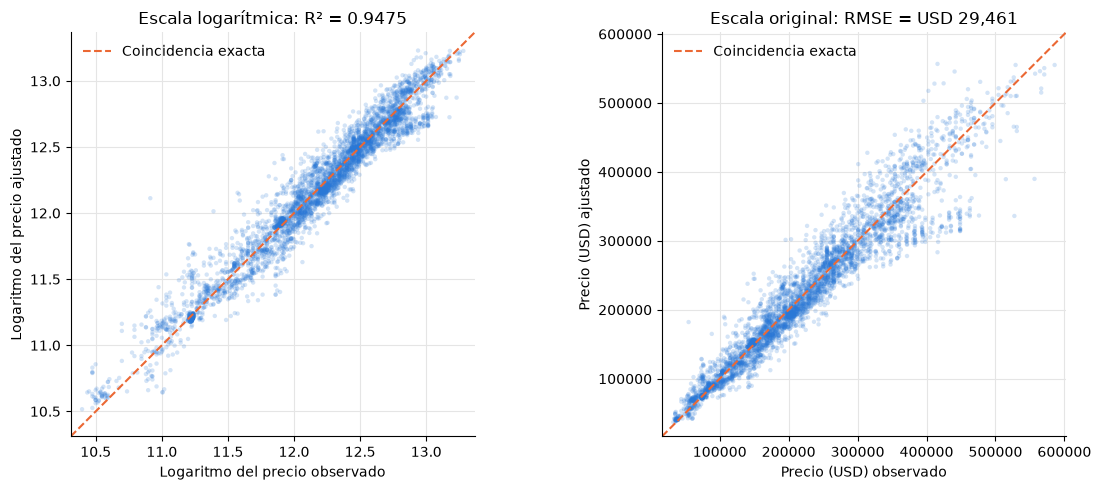

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
paneles_ajuste = [
    (observado_log, predicho_log, 'Logaritmo del precio',
     f'Escala logarítmica: R² = {modelo_final.rsquared:.4f}'),
    (precio_observado, precio_ajustado, 'Precio (USD)',
     f'Escala original: RMSE = USD {np.sqrt(np.mean(error_usd ** 2)):,.0f}')
]
for ax, (observado, ajustado, etiqueta, titulo) in zip(axes, paneles_ajuste):
    ax.scatter(observado, ajustado, s=10, alpha=0.2, color=AZUL, edgecolors='none')
    minimo = min(np.min(observado), np.min(ajustado))
    maximo = max(np.max(observado), np.max(ajustado))
    margen = 0.03 * (maximo - minimo)
    limites = (minimo - margen, maximo + margen)
    ax.plot(limites, limites, color=NARANJA, linestyle='--', linewidth=1.5,
            label='Coincidencia exacta')
    ax.set(xlim=limites, ylim=limites, xlabel=f'{etiqueta} observado',
           ylabel=f'{etiqueta} ajustado', title=titulo)
    ax.set_aspect('equal', adjustable='box')
    estilo(ax)
    ax.legend(frameon=False)
axes[1].ticklabel_format(style='plain', axis='both', useOffset=False)
plt.tight_layout()
plt.show()

**Que se observa:** La cercanía global a la diagonal es compatible con el R² alto. La separación vertical muestra errores que el resumen numérico no permite localizar; el panel en dólares ayuda a reconocer su magnitud en viviendas de distinto precio. La dispersión y los casos alejados deben leerse junto con el diagnóstico de residuos de la sección 5. Son valores ajustados de entrenamiento, no predicciones de validación; esta gráfica no demuestra generalización ni cumplimiento de los supuestos.

## 7. Cálculo de intervalos de confianza para los parámetros del modelo

### 7.1 Método de cálculo

Se calculan intervalos **individuales al 95 %** para los 22 parámetros del mismo `modelo_final`. Se conserva la covarianza robusta agrupada por los 26 conjuntos residenciales, con la corrección finita usada en la estimación y referencia $t$ con $G-1=25$ grados de libertad:

$$IC_{95\%}(\beta_j)=\widehat\beta_j\ \pm\ t_{0,975;25}\,\mathrm{EE}_{agrupado}(\widehat\beta_j).$$

Los intervalos permiten heterocedasticidad y dependencia dentro del conjunto, bajo independencia entre conjuntos. Son aproximados con 26 grupos y están condicionados a la especificación seleccionada: no incorporan la incertidumbre de la selección de variables. El 95 % es una cobertura de largo plazo del procedimiento, no una probabilidad asignada a un parámetro fijo después de observar los datos. Tampoco implica cobertura simultánea del 95 % para los 22 intervalos.

**Relación con el enfoque clásico.** Bajo errores normales, independientes y homocedásticos, el intervalo clásico utiliza $\widehat\beta_j\pm t_{0,975;n-p}\,\mathrm{EE}_{clásico}(\widehat\beta_j)$, con $n-p=4124-22=4102$ grados de libertad. En este análisis se conserva la referencia aproximada con **25 grados de libertad** porque la incertidumbre se estima agrupando por **26 conjuntos**, permitiendo dependencia dentro de cada uno. Cambian tanto los errores estándar como el valor crítico; no basta con reemplazar únicamente los grados de libertad. Esta extensión no se desarrolla en los dos archivos de clase suministrados y responde a la estructura de los datos y al diagnóstico de la sección 5.


In [48]:
# Intervalos para parámetros: no son intervalos de predicción de viviendas.
nivel_confianza = 0.95
alpha_ic = 1 - nivel_confianza
grupos_ic = train['complejo'].nunique()
gl_ic = grupos_ic - 1
assert modelo_final.cov_type == 'cluster' and modelo_final.use_t
assert modelo_final.df_resid_inference == gl_ic
t_critico_ic = stats.t.ppf(1 - alpha_ic / 2, df=gl_ic)
limites_ic = modelo_final.conf_int(alpha=alpha_ic)

intervalos_parametros = pd.DataFrame({
    'Coeficiente': modelo_final.params,
    'EE agrupado': modelo_final.bse,
    'LI 95 %': limites_ic.iloc[:, 0],
    'LS 95 %': limites_ic.iloc[:, 1]
})
# Verificar que statsmodels usa la misma referencia t agrupada.
assert np.allclose(intervalos_parametros['LI 95 %'],
                   modelo_final.params - t_critico_ic * modelo_final.bse)
assert np.allclose(intervalos_parametros['LS 95 %'],
                   modelo_final.params + t_critico_ic * modelo_final.bse)
print(f'Confianza: {nivel_confianza:.0%}; conjuntos: {grupos_ic}; gl: {gl_ic}; t crítico: {t_critico_ic:.4f}')
display(intervalos_parametros.round(6))

Confianza: 95%; conjuntos: 26; gl: 25; t crítico: 2.0595


,Coeficiente,EE agrupado,LI 95 %,LS 95 %
Intercept,11.915978,0.093179,11.724072,12.107884
C(YrSold)[T.2008],0.055834,0.027666,-0.001144,0.112813
C(YrSold)[T.2009],0.010610,0.044113,-0.080242,0.101462
C(YrSold)[T.2010],0.085102,0.029402,0.024547,0.145657
C(YrSold)[T.2011],0.181052,0.031758,0.115646,0.246459
C(YrSold)[T.2012],0.260379,0.046001,0.165637,0.355120
C(YrSold)[T.2013],0.340518,0.048960,0.239684,0.441353
C(YrSold)[T.2014],0.465644,0.054574,0.353246,0.578042
C(YrSold)[T.2015],0.643572,0.055112,0.530067,0.757077
C(YrSold)[T.2016],0.645820,0.047960,0.547044,0.744597


### 7.2 Lectura de los intervalos

El valor crítico es aproximadamente **2,0595**. Los intervalos están en la escala de los coeficientes de la ecuación logarítmica, con los centrados definidos en la sección 3.5 y el año 2007 como referencia de las indicadoras. Los intervalos del intercepto, cuadrados e interacciones no representan directamente cambios porcentuales del precio.

Para `Floor`, `MonthSold` y `Bloque`, que no participan en interacciones, un cambio unitario o de categoría puede expresarse como $100[\exp(\beta)-1]$ por ciento, manteniendo las demás explicativas constantes. Los extremos de su intervalo pueden transformarse con la misma función monótona. Esta lectura corresponde al cambio multiplicativo en la escala exponenciada del predictor logarítmico; no implica automáticamente un cambio en la media aritmética del precio.

**Año de venta y antigüedad.** El año también interviene mediante `Antig_c:YrSold_c`. Por ello, transformar únicamente el coeficiente de una indicadora de año describe la comparación con 2007 **a una antigüedad fija de 10 años**, cuando `Antig_c = 0`, manteniendo las demás explicativas constantes. Para el año $a$ y una antigüedad centrada fija $A_c$, la diferencia en el predictor logarítmico frente a 2007 es:

$$\Delta_a(A_c)=\beta_a+(a-2007)A_c\,\beta_{\mathrm{Antig_c:YrSold_c}}.$$

En esa comparación se mantiene fija la antigüedad, no el año de construcción. El cambio porcentual correspondiente es $100[\exp(\Delta_a(A_c))-1]$. Si $A_c\ne0$, su intervalo debe calcularse como una combinación lineal de coeficientes usando la matriz de covarianza agrupada completa: $\widehat\Delta\pm t_{0,975;25}\sqrt{c^\top\widehat V_{agrupada}c}$, donde $c$ selecciona los términos de la comparación. Después se transforman sus extremos. Los intervalos individuales de la tabla siguen siendo correctos para los parámetros; no se presentan como intervalos de estos efectos combinados.

El efecto del tamaño, la antigüedad y los parqueaderos también depende de otros valores del modelo por sus términos cuadrados o interacciones. El intervalo de un coeficiente aislado no es el intervalo de su efecto total; este último requiere combinar coeficientes y sus covarianzas.

Los intervalos de las indicadoras de **2008 y 2009** y del **cuadrado del log-tamaño centrado** incluyen cero; esto expresa incertidumbre sobre esos coeficientes y no obliga a retirar términos que forman parte de la estructura seleccionada. Los contrastes formales y la interpretación económica detallada corresponden a los siguientes apartados.

Estos intervalos cuantifican la incertidumbre de los **parámetros**. No son intervalos para el precio de una nueva vivienda ni corrigen posibles variables omitidas o una media mal especificada.

### 7.3 Visualización de los intervalos de confianza

Cada punto representa un coeficiente y cada segmento su intervalo individual al 95 %, con errores estándar agrupados. La línea vertical en cero facilita identificar intervalos que lo contienen. Los parámetros se separan en paneles con escalas horizontales propias para evitar que el intercepto o los efectos más grandes oculten los coeficientes pequeños. Se incluyen los 22 parámetros.

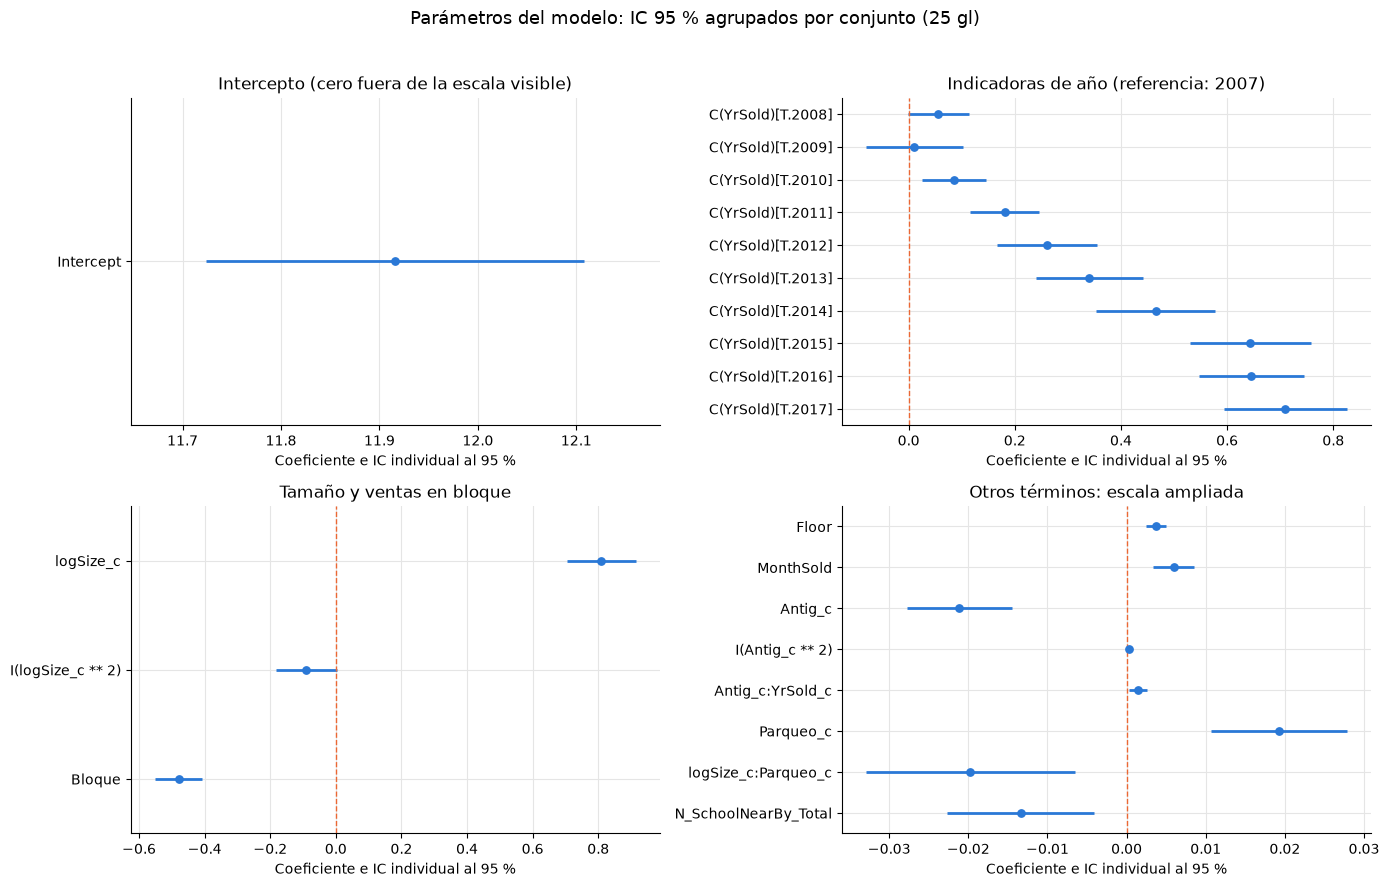

In [50]:
grupos_grafico_ic = {
    'Intercepto': ['Intercept'],
    'Indicadoras de año (referencia: 2007)': [
        nombre for nombre in intervalos_parametros.index if nombre.startswith('C(YrSold)')],
    'Tamaño y ventas en bloque': ['logSize_c', 'I(logSize_c ** 2)', 'Bloque'],
    'Otros términos: escala ampliada': [
        'Floor', 'MonthSold', 'Antig_c', 'I(Antig_c ** 2)',
        'Antig_c:YrSold_c', 'Parqueo_c', 'logSize_c:Parqueo_c', 'N_SchoolNearBy_Total']
}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (titulo, nombres) in zip(axes.flat, grupos_grafico_ic.items()):
    datos_ic = intervalos_parametros.loc[nombres]
    posiciones = np.arange(len(datos_ic))
    ax.hlines(posiciones, datos_ic['LI 95 %'], datos_ic['LS 95 %'],
              color=AZUL, linewidth=2)
    ax.scatter(datos_ic['Coeficiente'], posiciones, color=AZUL, s=28, zorder=3)
    ax.axvline(0, color=NARANJA, linestyle='--', linewidth=1)
    ax.set_yticks(posiciones, labels=datos_ic.index)
    ax.set(xlabel='Coeficiente e IC individual al 95 %', title=titulo,
           ylim=(len(datos_ic) - 0.5, -0.5))
    # En el panel del intercepto se prioriza la lectura de su intervalo.
    # Cero queda fuera del rango visible y se indica explícitamente.
    if titulo == 'Intercepto':
        ancho_ic = float((datos_ic['LS 95 %'] - datos_ic['LI 95 %']).iloc[0])
        ax.set_xlim(float(datos_ic['LI 95 %'].iloc[0]) - 0.2 * ancho_ic,
                    float(datos_ic['LS 95 %'].iloc[0]) + 0.2 * ancho_ic)
        ax.set_title('Intercepto (cero fuera de la escala visible)')
    estilo(ax)
fig.suptitle('Parámetros del modelo: IC 95 % agrupados por conjunto (25 gl)', fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Que se observa:** Los intervalos de 2008, 2009 y del cuadrado del log-tamaño centrado cruzan cero. Los demás quedan a un lado de cero, incluido el pequeño coeficiente cuadrático de antigüedad. La anchura refleja incertidumbre en las unidades de cada parámetro: no debe compararse directamente entre paneles como una medida de importancia económica. Los efectos de año corresponden a antigüedad de 10 años; para otras antigüedades se necesita el efecto combinado explicado en 7.2.